(mmm_current_vs_future_value)=
# Current vs Future Media Value: Splitting Contributions by When They Land

A media mix model (MMM) tells us how much each channel contributed. Finance and media teams then ask two different questions of that same number:

- **Media planning** asks: *what did this month's spend buy?* That includes the carryover that keeps arriving in the weeks after the spend.
- **Finance** asks: *how much of that value showed up this month, and how much will show up later?* A quarter's spend that pays off in the next quarter should be booked there.

Both questions are about *when* the effect of spend lands. Adstock spreads the response to one week's spend over the following weeks. So the value of a period's spend splits into two parts:

- **Current value**: the part that lands in the same reporting period as the spend.
- **Future value**: the carryover that lands after the period ends.

In this notebook we fit an MMM on synthetic data where we know the truth, and walk from the model's contributions to that split, one step at a time. Then we repeat the split on real data, with the model of the case study:

1. We fit the model and check the usual diagnostics.
2. We look at the two ways of reading a contribution: by the date it lands on, and by the spend period that caused it.
3. We lay both readings out in one object, the **carryover matrix**: rows are spend periods, columns are the dates the effect lands on.
4. We reduce the matrix to current and future value, and compare the result with the truth.
5. We look at the shortcut behind it, the cumulative adstock weights, and at `method="closed_form"`, which computes the same numbers without simulating each period.
6. We fit the case study's model, which uses the default transformation order, `adstock_first=True`, and compare the two ways the split can be defined there.

The methods we use are opt-in. They do not change any existing output of the model.

## Prepare Notebook

In [1]:
import time
import warnings

import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from pymc_extras.prior import Prior

from pymc_marketing.data.idata.utils import subsample_draws
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation
from pymc_marketing.paths import data_dir

warnings.filterwarnings("ignore", category=FutureWarning)

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 7]
plt.rcParams["figure.dpi"] = 100

%config InlineBackend.figure_format = "retina"

In [2]:
seed: int = sum(map(ord, "mmm_current_vs_future_value"))
rng: np.random.Generator = np.random.default_rng(seed=seed)

## The Idea in One Picture

Take one channel with a geometric adstock. One unit of response to spend in week $s$ lands as $w_0$ in week $s$, $w_1$ in week $s+1$, and so on up to $w_{l_{\max}-1}$. With `normalize=True` the weights sum to one, so they say *which share of the effect lands in which week*.

Now report monthly. Spend in the first week of January has three more January weeks to land in. Spend in the last week of January has none. The same kernel therefore gives a different current share depending on where in the month the spend falls.

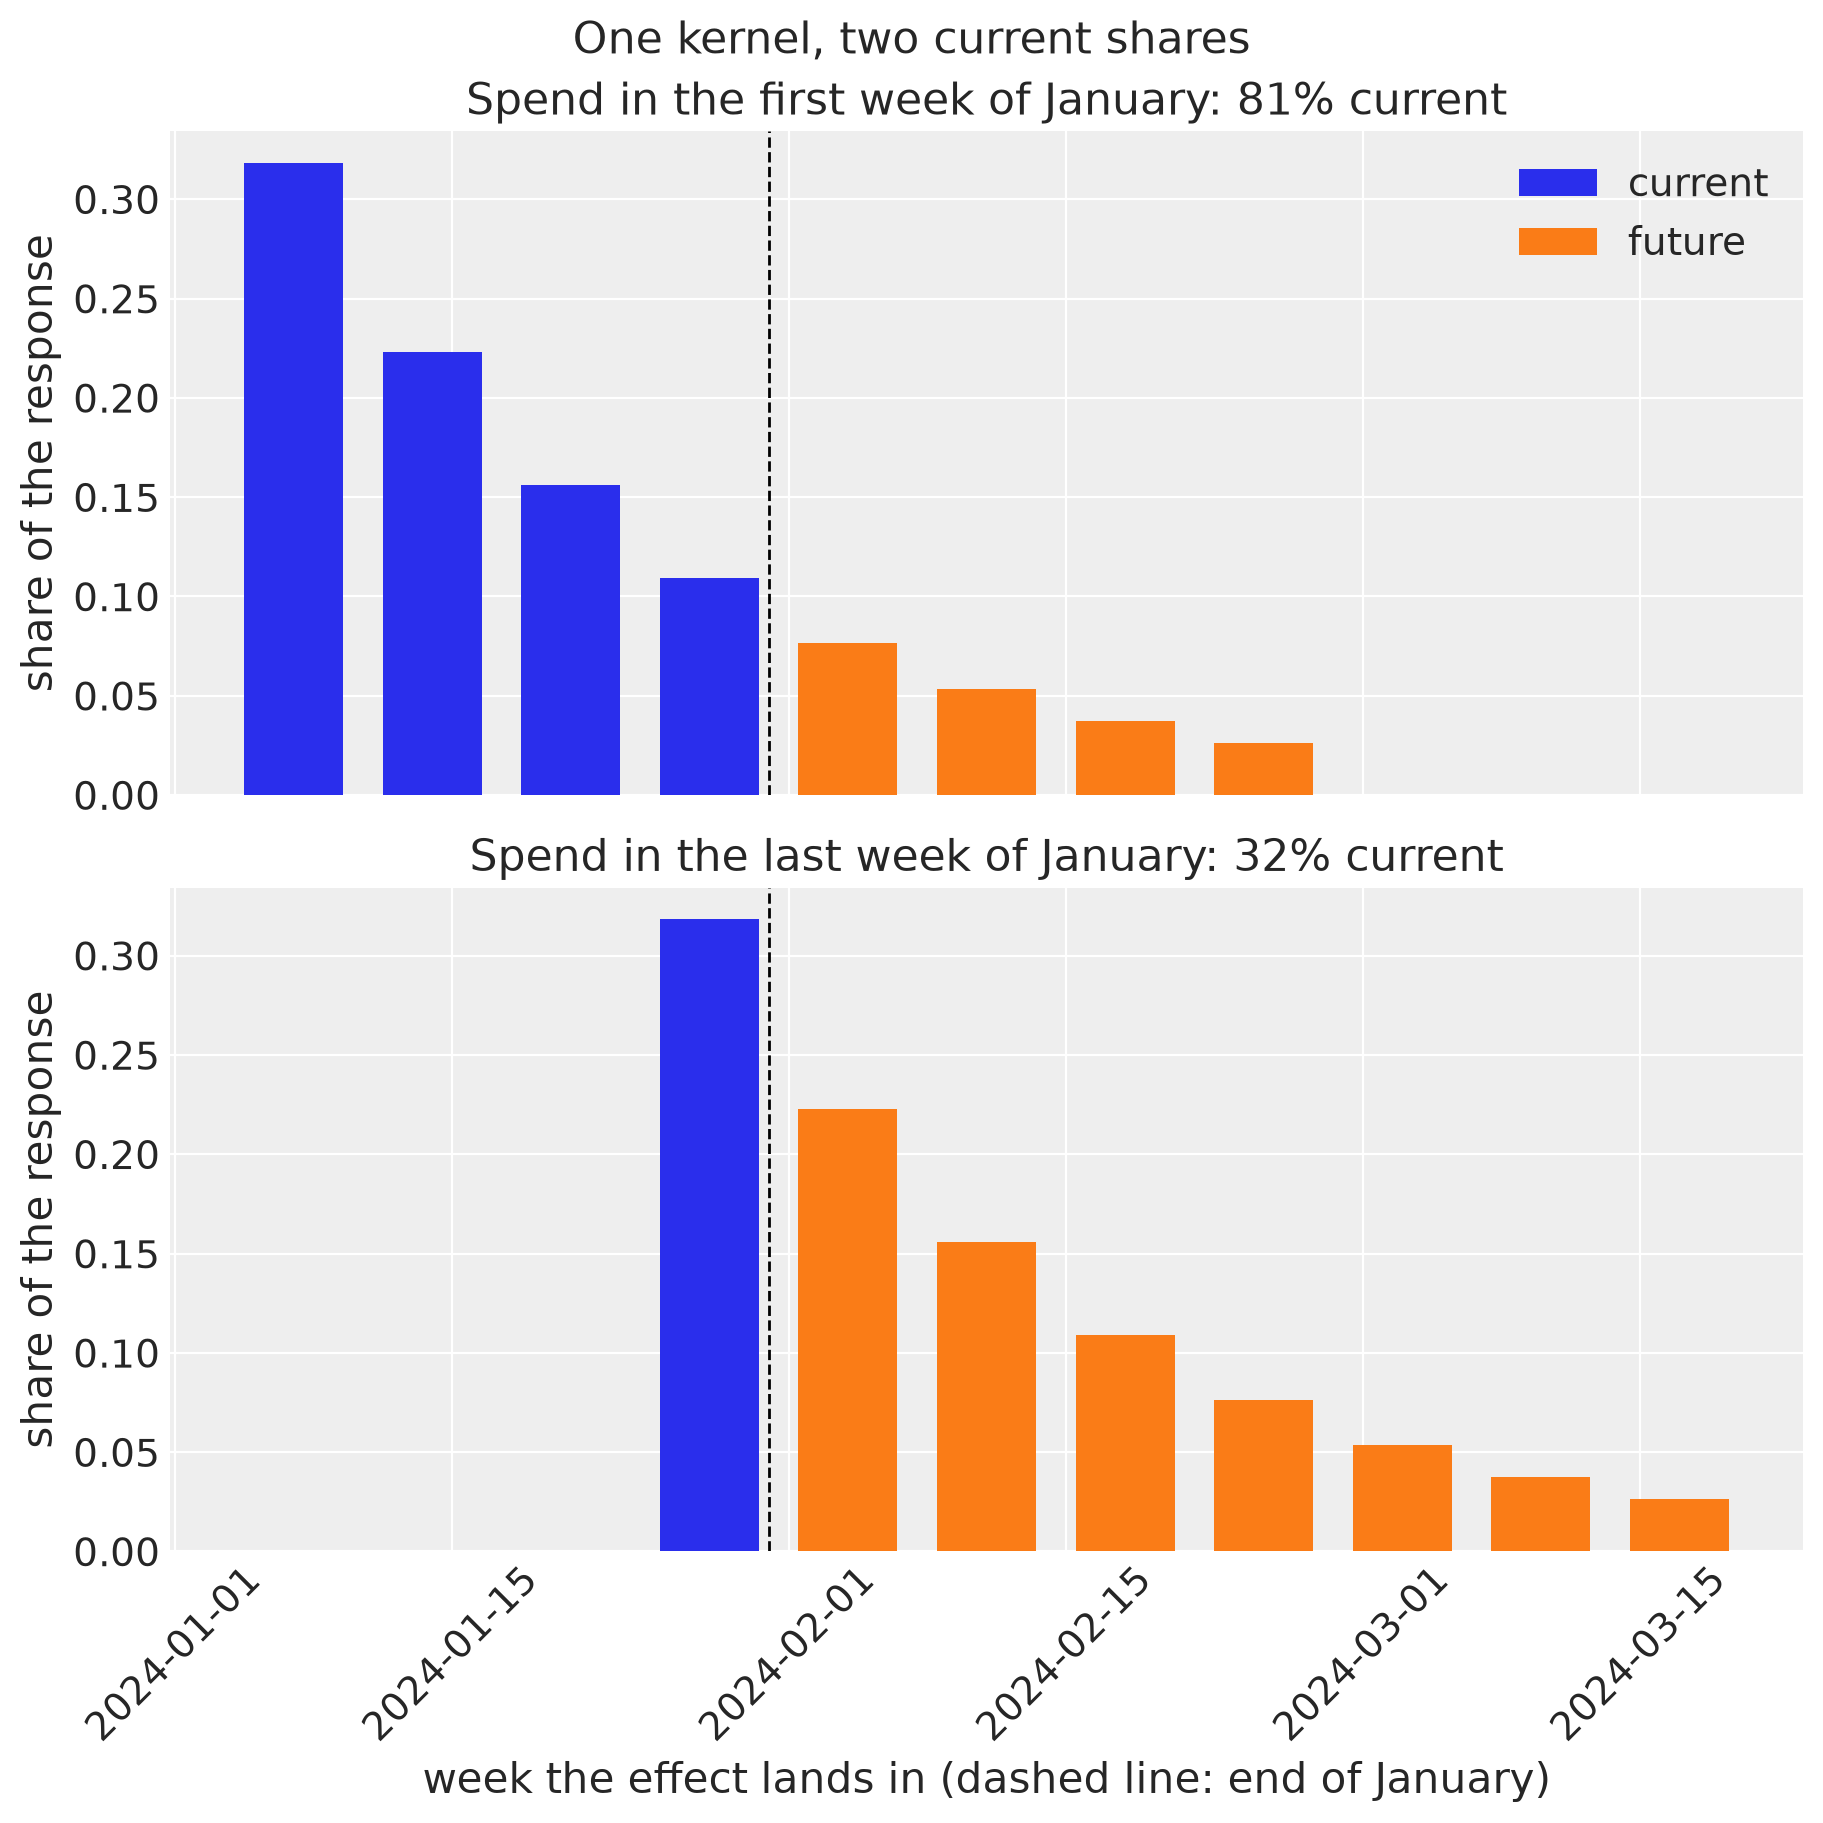

In [3]:
def geometric_kernel(alpha: float, l_max: int) -> np.ndarray:
    # Normalized geometric adstock weights on lags 0 .. l_max - 1.
    weights = alpha ** np.arange(l_max)
    return weights / weights.sum()


kernel = geometric_kernel(alpha=0.7, l_max=8)
weeks = pd.date_range("2024-01-07", periods=12, freq="W-SUN")
month_end = pd.Timestamp("2024-01-31")

fig, axes = plt.subplots(
    2, 1, figsize=(9, 9), sharex=True, sharey=True, layout="constrained"
)
for ax, spend_week, label in zip(
    axes, [0, 3], ["first week of January", "last week of January"], strict=True
):
    landing = weeks[spend_week : spend_week + len(kernel)]
    current = np.asarray(landing <= month_end)
    ax.bar(landing[current], kernel[current], width=5, color="C0", label="current")
    ax.bar(landing[~current], kernel[~current], width=5, color="C1", label="future")
    ax.axvline(month_end, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=f"Spend in the {label}: {kernel[current].sum():.0%} current",
        ylabel="share of the response",
    )
axes[1].set_xlabel("week the effect lands in (dashed line: end of January)")
axes[1].tick_params(axis="x", rotation=45)
axes[0].legend()
fig.suptitle("One kernel, two current shares", fontsize=16);

That is the whole idea. The rest of the notebook does the same bookkeeping with a fitted model, with posterior uncertainty, and on every channel and month at once.

## Synthetic Data

We simulate three years of weekly sales with three channels that carry over at very different speeds:

| channel | spend pattern | true adstock $\alpha$ | carryover |
|---|---|---|---|
| `tv` | flighted: 5 weeks on, 8 weeks off | 0.70 | slow |
| `social` | pulsed, on in about 60% of weeks | 0.45 | medium |
| `search` | always on, with a yearly cycle | 0.15 | fast |

The data generating process applies **saturation first and adstock second**. For channel $c$ in week $t$,

$$
V_{c,t} = \beta_c \, \frac{1 - e^{-\lambda_c x_{c,t}}}{1 + e^{-\lambda_c x_{c,t}}},
\qquad
\text{contribution}_{c,t} = \sum_{l=0}^{l_{\max}-1} w_{c,l} \, V_{c,t-l},
$$

where $x_{c,t}$ is spend divided by its maximum and $w_{c,l}$ are the normalized geometric weights. Each week's spend saturates on its own, and its saturated value $V_{c,s}$ is then spread over the following weeks by the kernel. Sales add a baseline, a yearly cycle, a promotion effect and noise.

In [4]:
n_weeks = 156
L_MAX = 8
channels = ["tv", "social", "search"]
dates = pd.date_range("2022-01-02", periods=n_weeks, freq="W-SUN")
week = np.arange(n_weeks)

true_alpha = {"tv": 0.70, "social": 0.45, "search": 0.15}
true_lam = {"tv": 2.0, "social": 2.5, "search": 3.0}
true_beta = {"tv": 600.0, "social": 300.0, "search": 350.0}

spend = pd.DataFrame(
    {
        "tv": rng.gamma(4.0, 1_500, n_weeks) * (week % 13 < 5),
        "social": rng.gamma(2.0, 900, n_weeks) * (rng.random(n_weeks) < 0.6),
        "search": rng.gamma(9.0, 300, n_weeks)
        * (1 + 0.3 * np.sin(2 * np.pi * week / 52)),
    },
    index=dates,
)


def logistic_saturation(x: np.ndarray, lam: float) -> np.ndarray:
    return (1 - np.exp(-lam * x)) / (1 + np.exp(-lam * x))


true_kernel = {c: geometric_kernel(true_alpha[c], L_MAX) for c in channels}
true_saturated = pd.DataFrame(
    {
        c: true_beta[c] * logistic_saturation(spend[c] / spend[c].max(), true_lam[c])
        for c in channels
    },
    index=dates,
)
true_contribution = pd.DataFrame(
    {c: np.convolve(true_saturated[c], true_kernel[c])[:n_weeks] for c in channels},
    index=dates,
)

promo = (rng.random(n_weeks) < 0.15).astype(float)
sales = (
    2_000
    + true_contribution.sum(axis=1).to_numpy()
    + 120 * np.sin(2 * np.pi * week / 52)
    + 150 * promo
    + rng.normal(0, 50, n_weeks)
)

data = pd.DataFrame(
    {"date": dates, **{c: spend[c].to_numpy() for c in channels}, "promo": promo}
)
X = data
y = pd.Series(sales, name="sales")
data.head().style.format(
    {"date": "{:%Y-%m-%d}", **dict.fromkeys(channels, "{:,.2f}"), "promo": "{:.0f}"}
)

,date,tv,social,search,promo
0,2022-01-02,"3,788.35","1,907.54","3,162.34",0
1,2022-01-09,"8,346.48","3,317.44","3,849.73",0
2,2022-01-16,"5,293.22","3,980.97","2,292.64",0
3,2022-01-23,"2,656.49","1,278.08","2,207.10",0
4,2022-01-30,"2,204.51","1,633.90","3,239.34",0


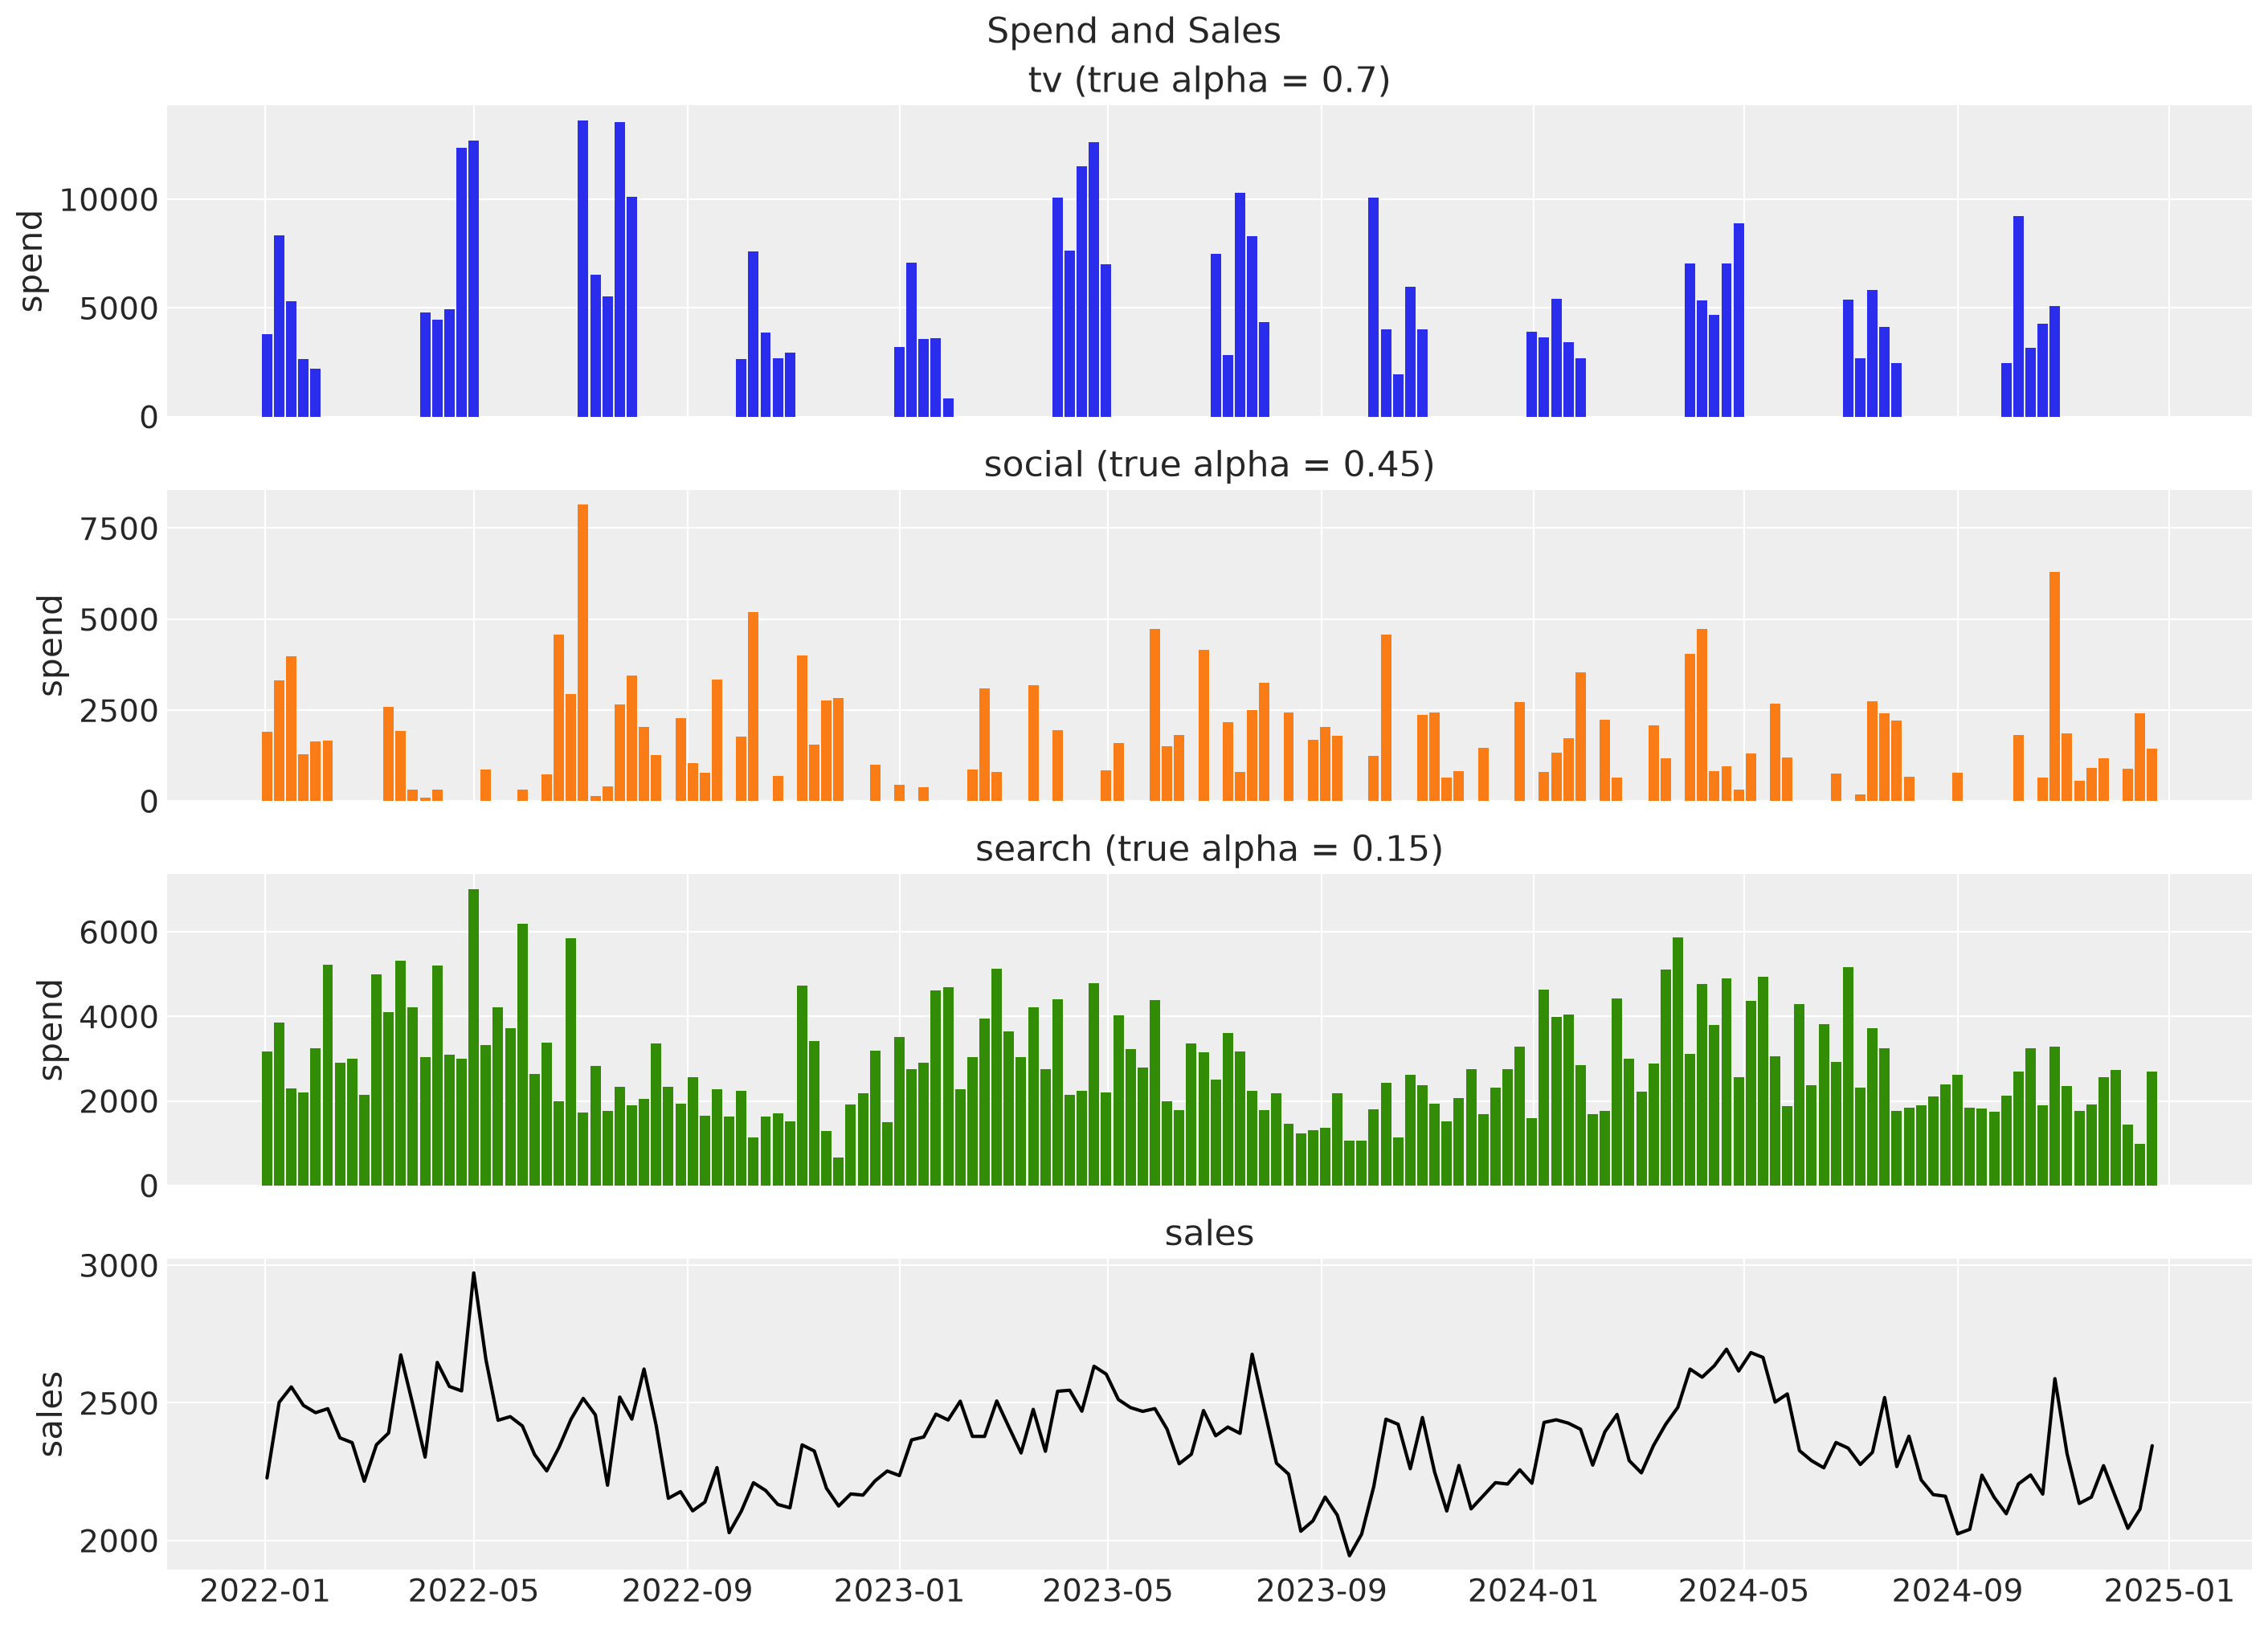

In [5]:
fig, axes = plt.subplots(nrows=4, figsize=(14, 10), sharex=True, layout="constrained")
for ax, channel in zip(axes, channels, strict=False):
    ax.bar(dates, spend[channel], width=6, color=f"C{channels.index(channel)}")
    ax.set(ylabel="spend", title=f"{channel} (true alpha = {true_alpha[channel]})")
axes[-1].plot(dates, sales, color="black")
axes[-1].set(ylabel="sales", title="sales")
fig.suptitle("Spend and Sales", fontsize=16);

## Model Specification

We use `MMM` with the structure of the data generating process: a `GeometricAdstock` with `l_max=8`, a `LogisticSaturation`, the promotion as a control, two yearly Fourier modes, and `adstock_first=False` so that saturation is applied first.

```{note}
The transformation order matters for this notebook. With saturation first, the model is additively separable across spend weeks: the response to one week's spend does not depend on any other week's spend. Then the two ways of attributing a date's contribution to the weeks that caused it, zeroing a period's spend (the *counterfactual*) and splitting the date's contribution by shares (the *allocation*), give the same numbers, and `method="closed_form"` applies. With the default `adstock_first=True` the current/future split is still available through the pipeline, but the two estimands differ; a section near the end fits such a model. See {meth}`~pymc_marketing.mmm.incrementality.Incrementality.split_incremental_contribution_over_time`.
```

In [6]:
mmm = MMM(
    date_column="date",
    channel_columns=channels,
    target_column="sales",
    control_columns=["promo"],
    yearly_seasonality=2,
    adstock=GeometricAdstock(l_max=L_MAX),
    saturation=LogisticSaturation(),
    adstock_first=False,
)
mmm.plot_suite = "new"

## Model Fitting

We fit on the full dataset with `nutpie`.

In [7]:
mmm.fit(
    X=X,
    y=y,
    chains=4,
    draws=1_000,
    tune=1_500,
    target_accept=0.9,
    nuts_sampler="nutpie",
    random_seed=rng,
)
mmm.sample_posterior_predictive(X, extend_idata=True, combined=True, random_seed=rng);

NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


Output()

Output()

Sampling: [y]


Output()

## Diagnostics

Before we read anything off the model, we check that the sampler did its job and that the model reproduces the data.

In [8]:
n_divergences = mmm.idata["sample_stats"]["diverging"].sum().item()
print(f"Number of divergences: {n_divergences}")

var_names = [
    "intercept_contribution",
    "adstock_alpha",
    "saturation_lam",
    "saturation_beta",
    "gamma_control",
    "gamma_fourier",
    "y_sigma",
]
summary = az.summary(mmm.idata, var_names=var_names)
summary[["mean", "sd", "r_hat", "ess_bulk", "ess_tail"]]

Number of divergences: 0


,mean,sd,r_hat,ess_bulk,ess_tail
intercept_contribution,0.6704,0.0109,1.00,1350,1350
adstock_alpha[tv],0.7067,0.0283,1.00,4799,3191
adstock_alpha[social],0.52,0.09,1.00,3169,2761
adstock_alpha[search],0.203,0.076,1.00,2069,2024
saturation_lam[tv],1.49,0.68,1.00,799,747
saturation_lam[social],2.34,1.35,1.00,953,884
saturation_lam[search],1.63,0.85,1.01,504,614
saturation_beta[tv],0.33,0.23,1.00,791,746
saturation_beta[social],0.17,0.18,1.01,899,817
saturation_beta[search],0.28,0.24,1.01,486,623


In [9]:
# az.summary rounds for display; compute the thresholds on the exact values.
sampled = mmm.idata.posterior.dataset[var_names]
r_hat = az.rhat(sampled)
ess_bulk = az.ess(sampled, method="bulk")
ess_tail = az.ess(sampled, method="tail")
print(f"max r_hat:    {max(float(r_hat[v].max()) for v in var_names):.4f}")
print(f"min ess_bulk: {min(float(ess_bulk[v].min()) for v in var_names):.0f}")
print(f"min ess_tail: {min(float(ess_tail[v].min()) for v in var_names):.0f}")

max r_hat:    1.0087
min ess_bulk: 486
min ess_tail: 614


No divergences, every $\hat{R}$ below 1.01 and every effective sample size above 400. The lowest effective sample sizes belong to the saturation parameters of `search`: its spend is always on, so the data rarely show it near zero, and $\beta$ and $\lambda$ can trade off along a ridge. The adstock $\alpha$, which drives everything in this notebook, mixes much better.

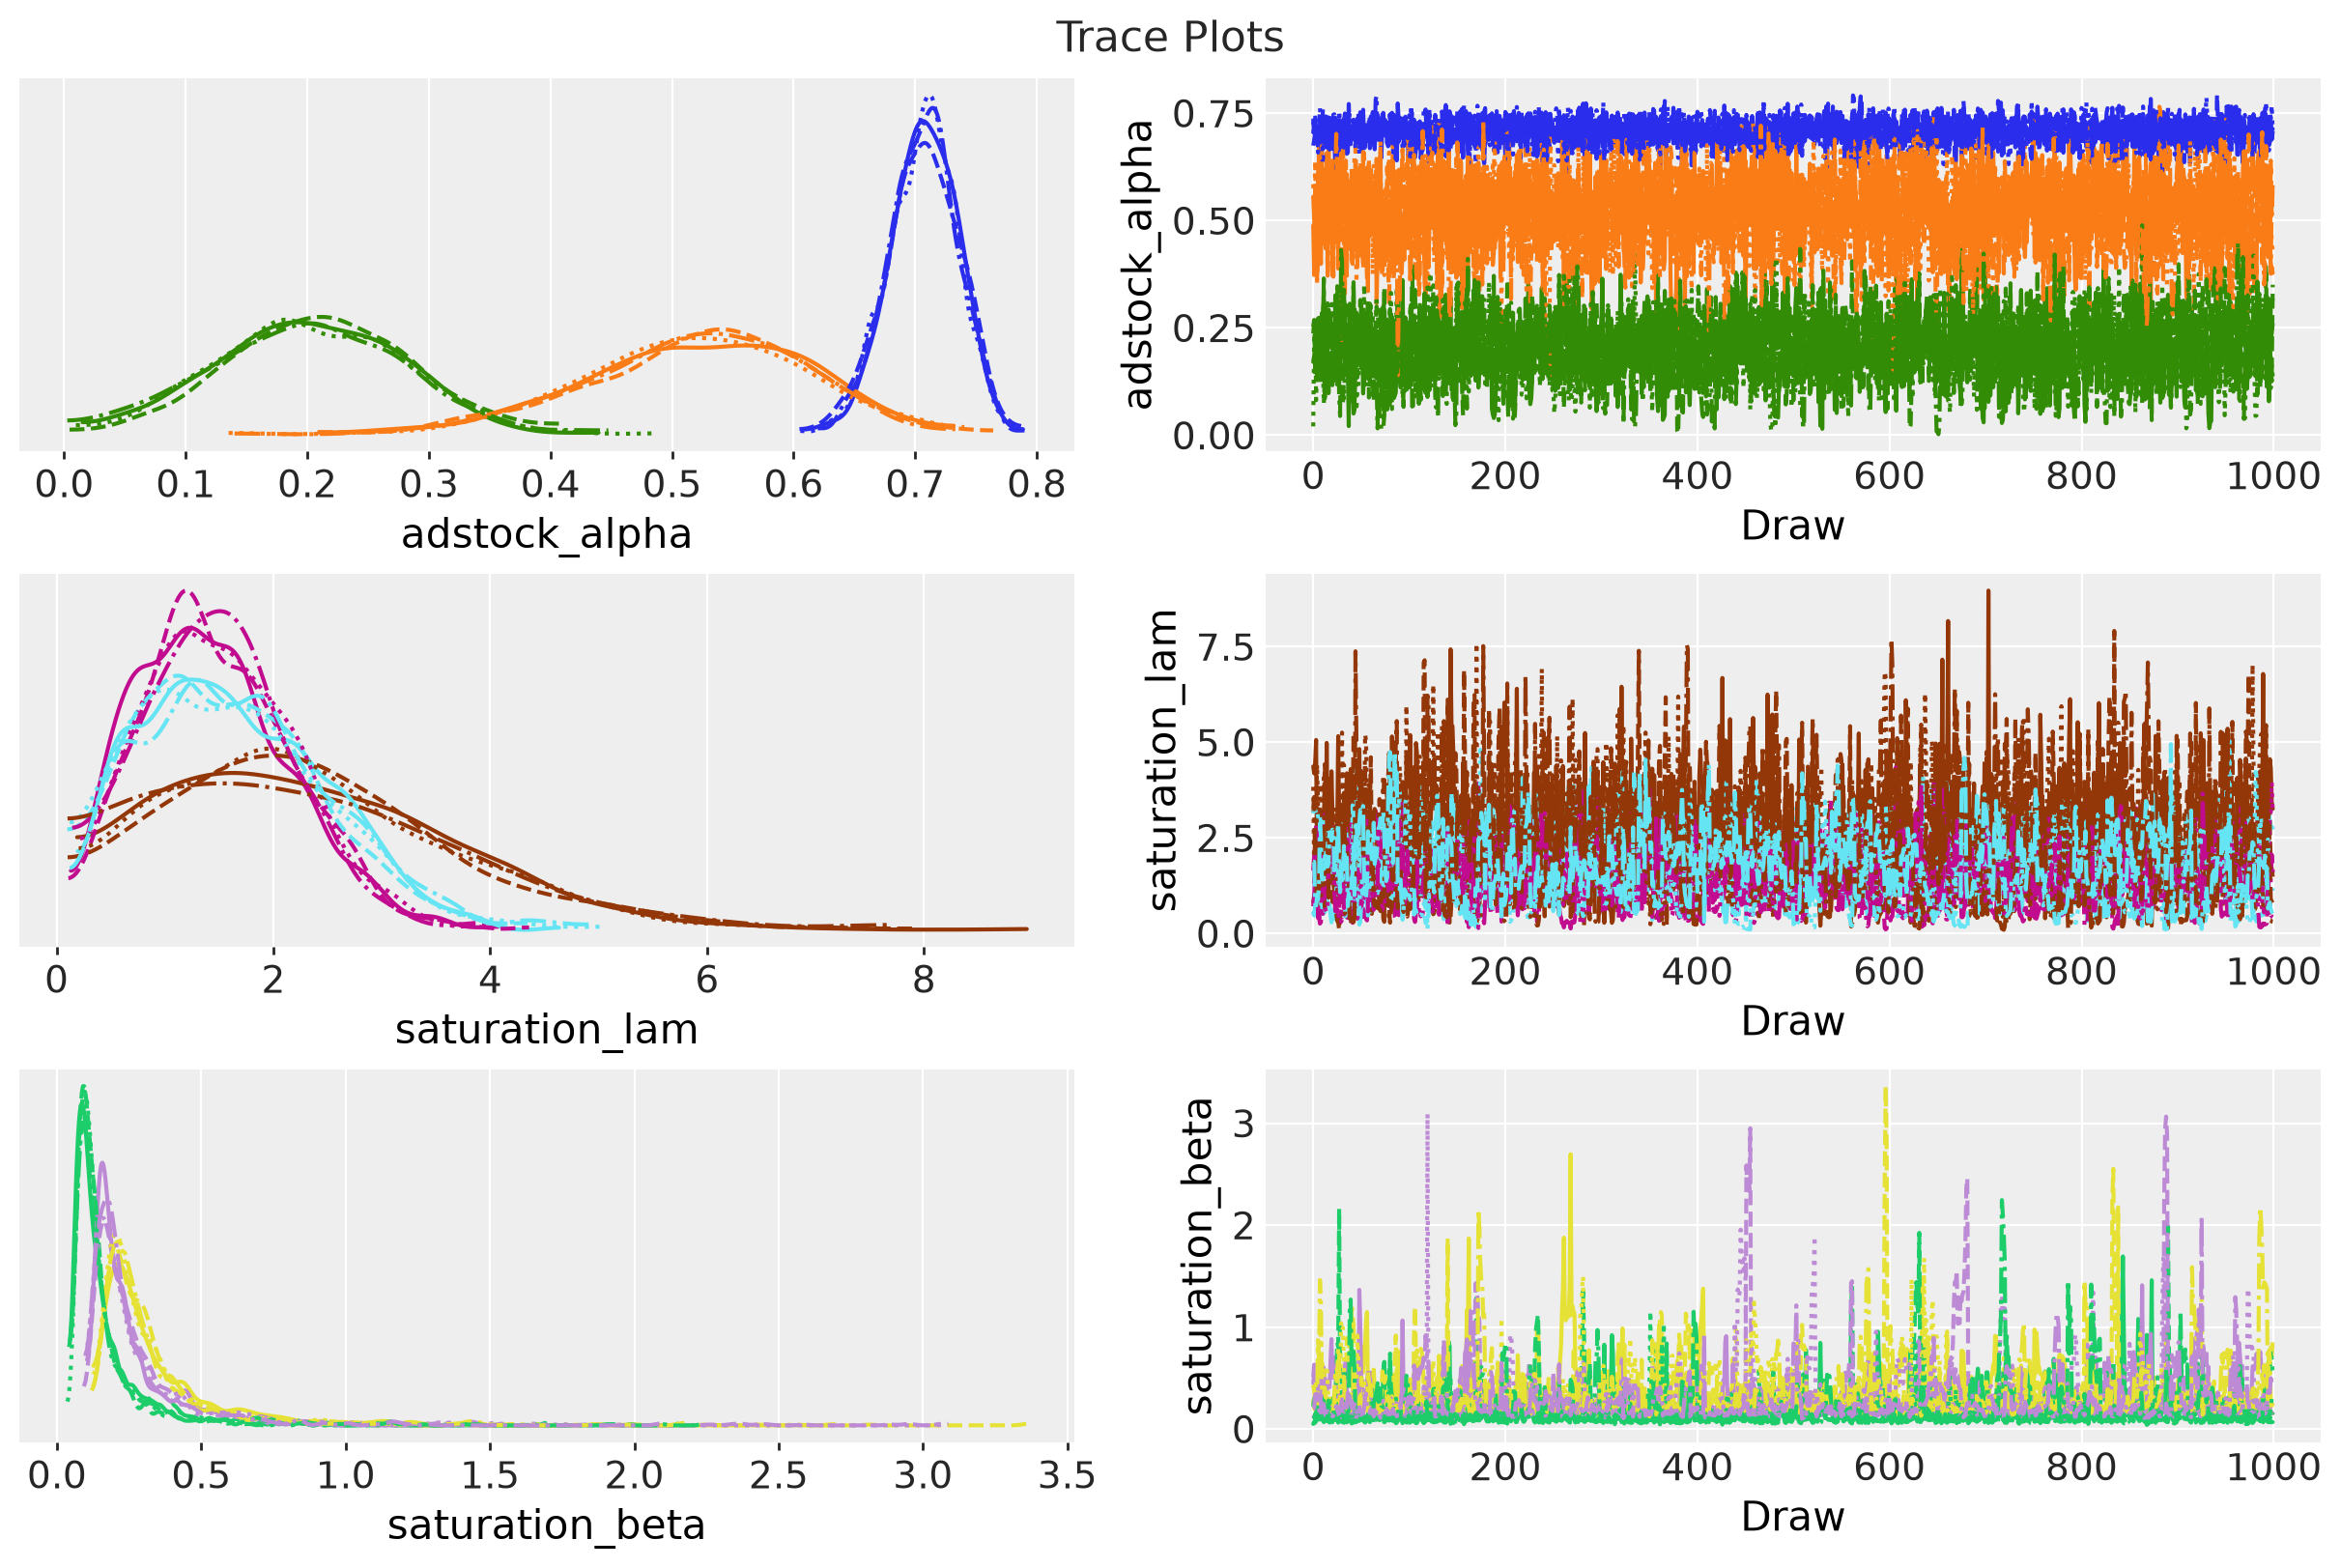

In [10]:
_ = azp.plot_trace_dist(
    mmm.fit_result,
    var_names=["adstock_alpha", "saturation_lam", "saturation_beta"],
    figure_kwargs={"figsize": (12, 8)},
)
plt.gcf().suptitle("Trace Plots", fontsize=16);

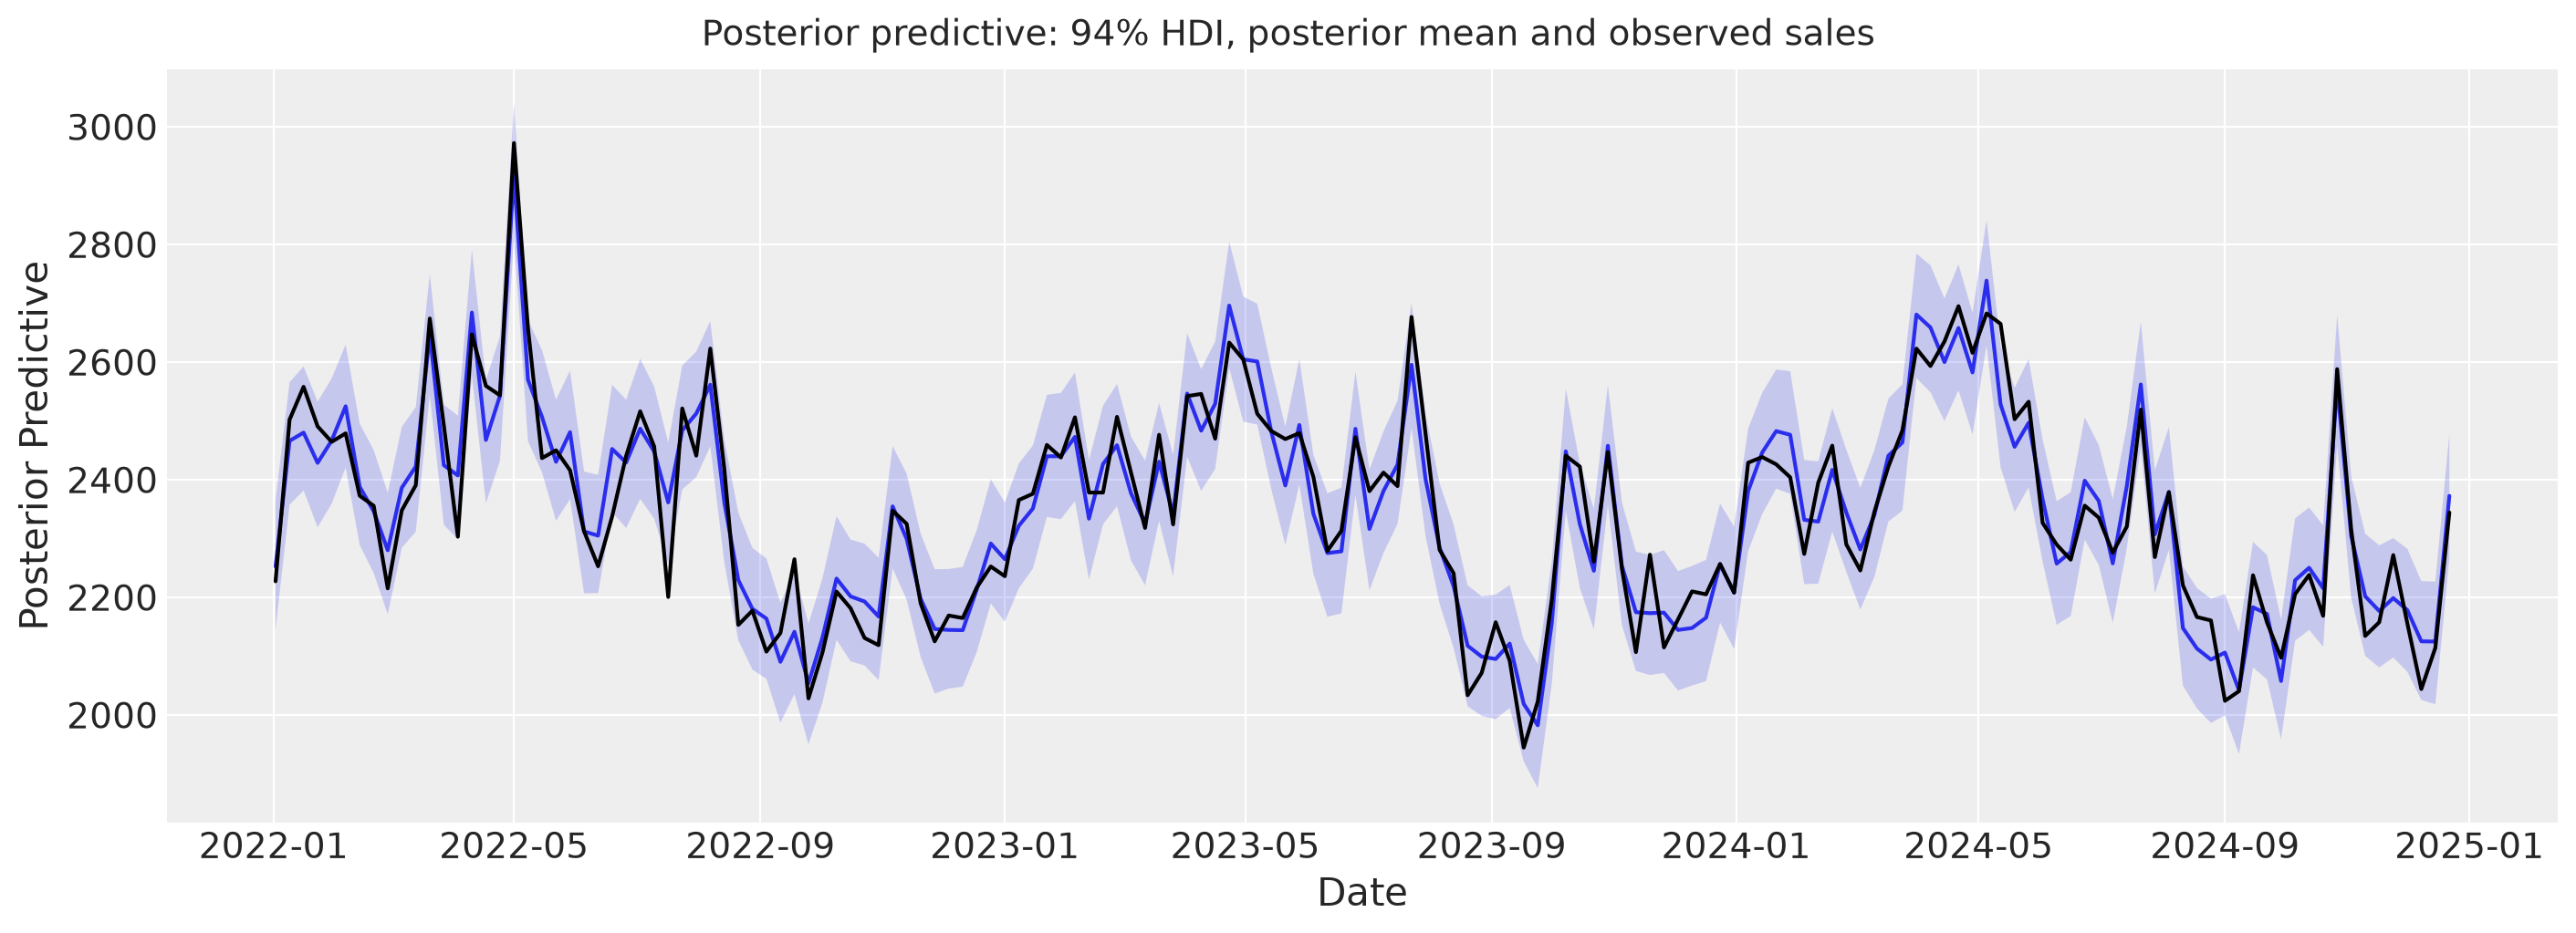

In [11]:
fig, axes = mmm.plot.diagnostics.posterior_predictive(figsize=(14, 5))
fig.suptitle(
    "Posterior predictive: 94% HDI, posterior mean and observed sales", fontsize=14
);

The adstock parameter is the one this notebook leans on most, so let's check that the model recovers it. The current/future split is mostly a statement about $\alpha$.

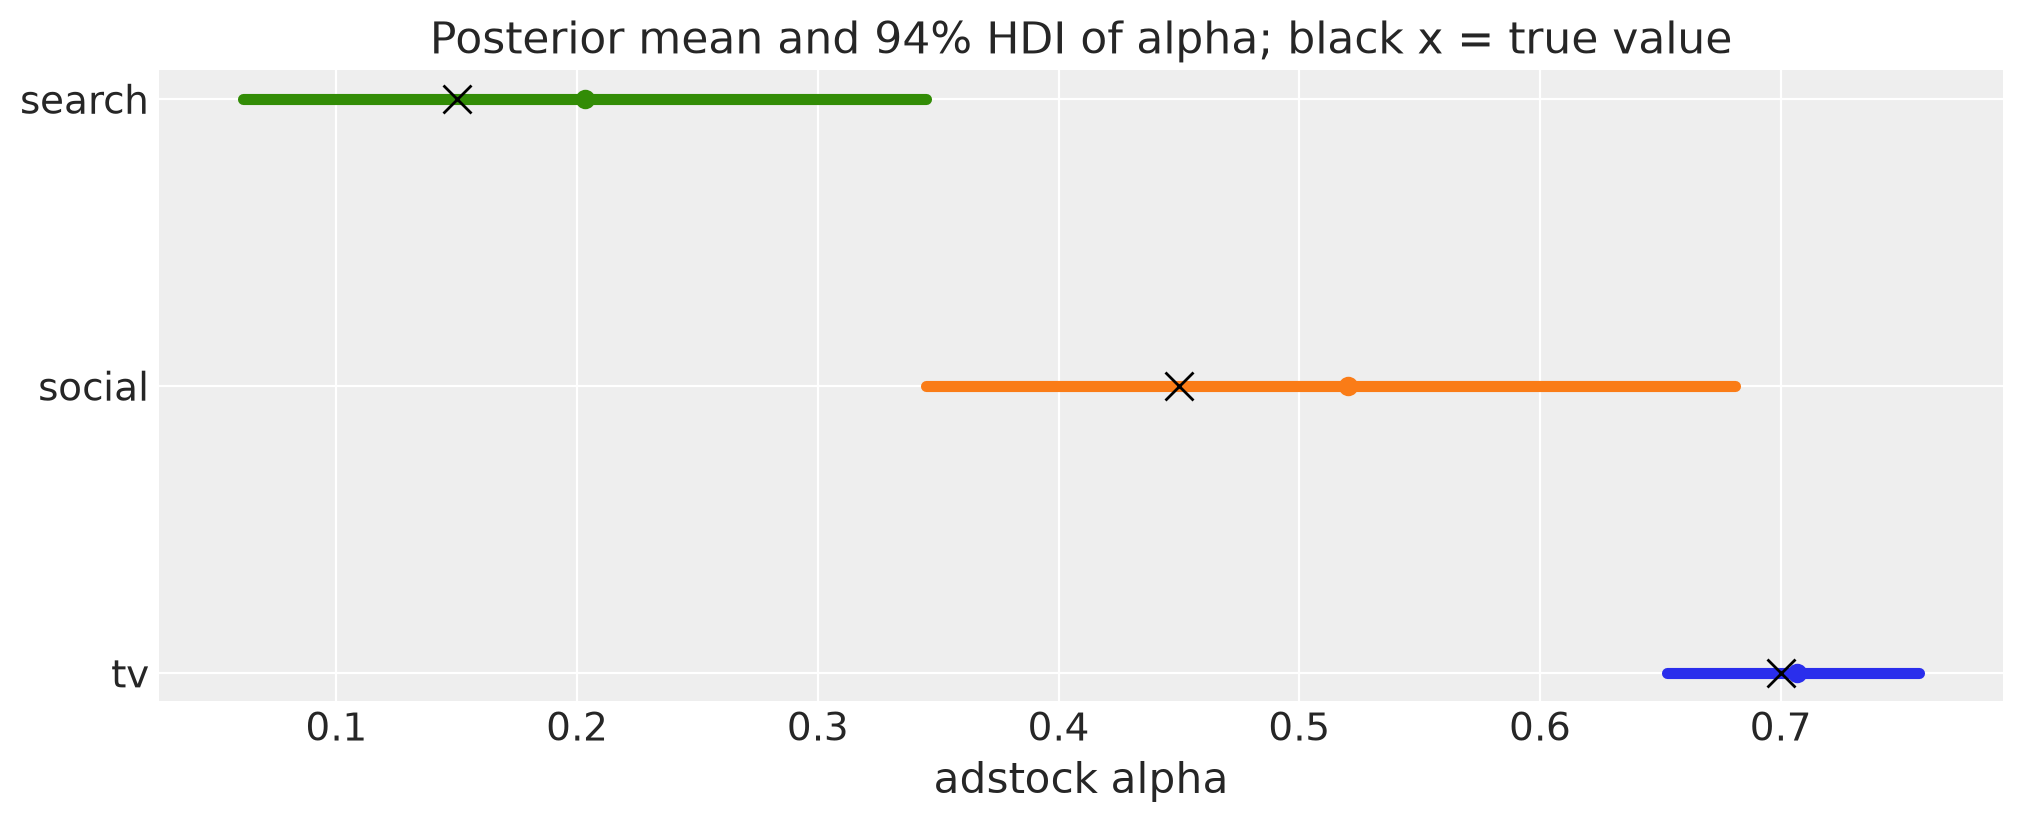

In [12]:
alpha = mmm.idata.posterior["adstock_alpha"]
alpha_hdi = az.hdi(alpha, prob=0.94)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for i, channel in enumerate(channels):
    interval = alpha_hdi.sel(channel=channel)
    lower = float(interval.sel(ci_bound="lower"))
    upper = float(interval.sel(ci_bound="upper"))
    ax.plot([lower, upper], [i, i], color=f"C{i}", linewidth=4)
    ax.plot(float(alpha.sel(channel=channel).mean()), i, "o", color=f"C{i}")
    ax.plot(true_alpha[channel], i, "x", color="black", markersize=10)
ax.set(
    yticks=range(len(channels)),
    yticklabels=channels,
    xlabel="adstock alpha",
    title="Posterior mean and 94% HDI of alpha; black x = true value",
);

## Two Ways to Read a Contribution

The model's `channel_contribution` answers the question *how much did channel $c$ add to sales in week $t$?* Let's first check it against the truth.

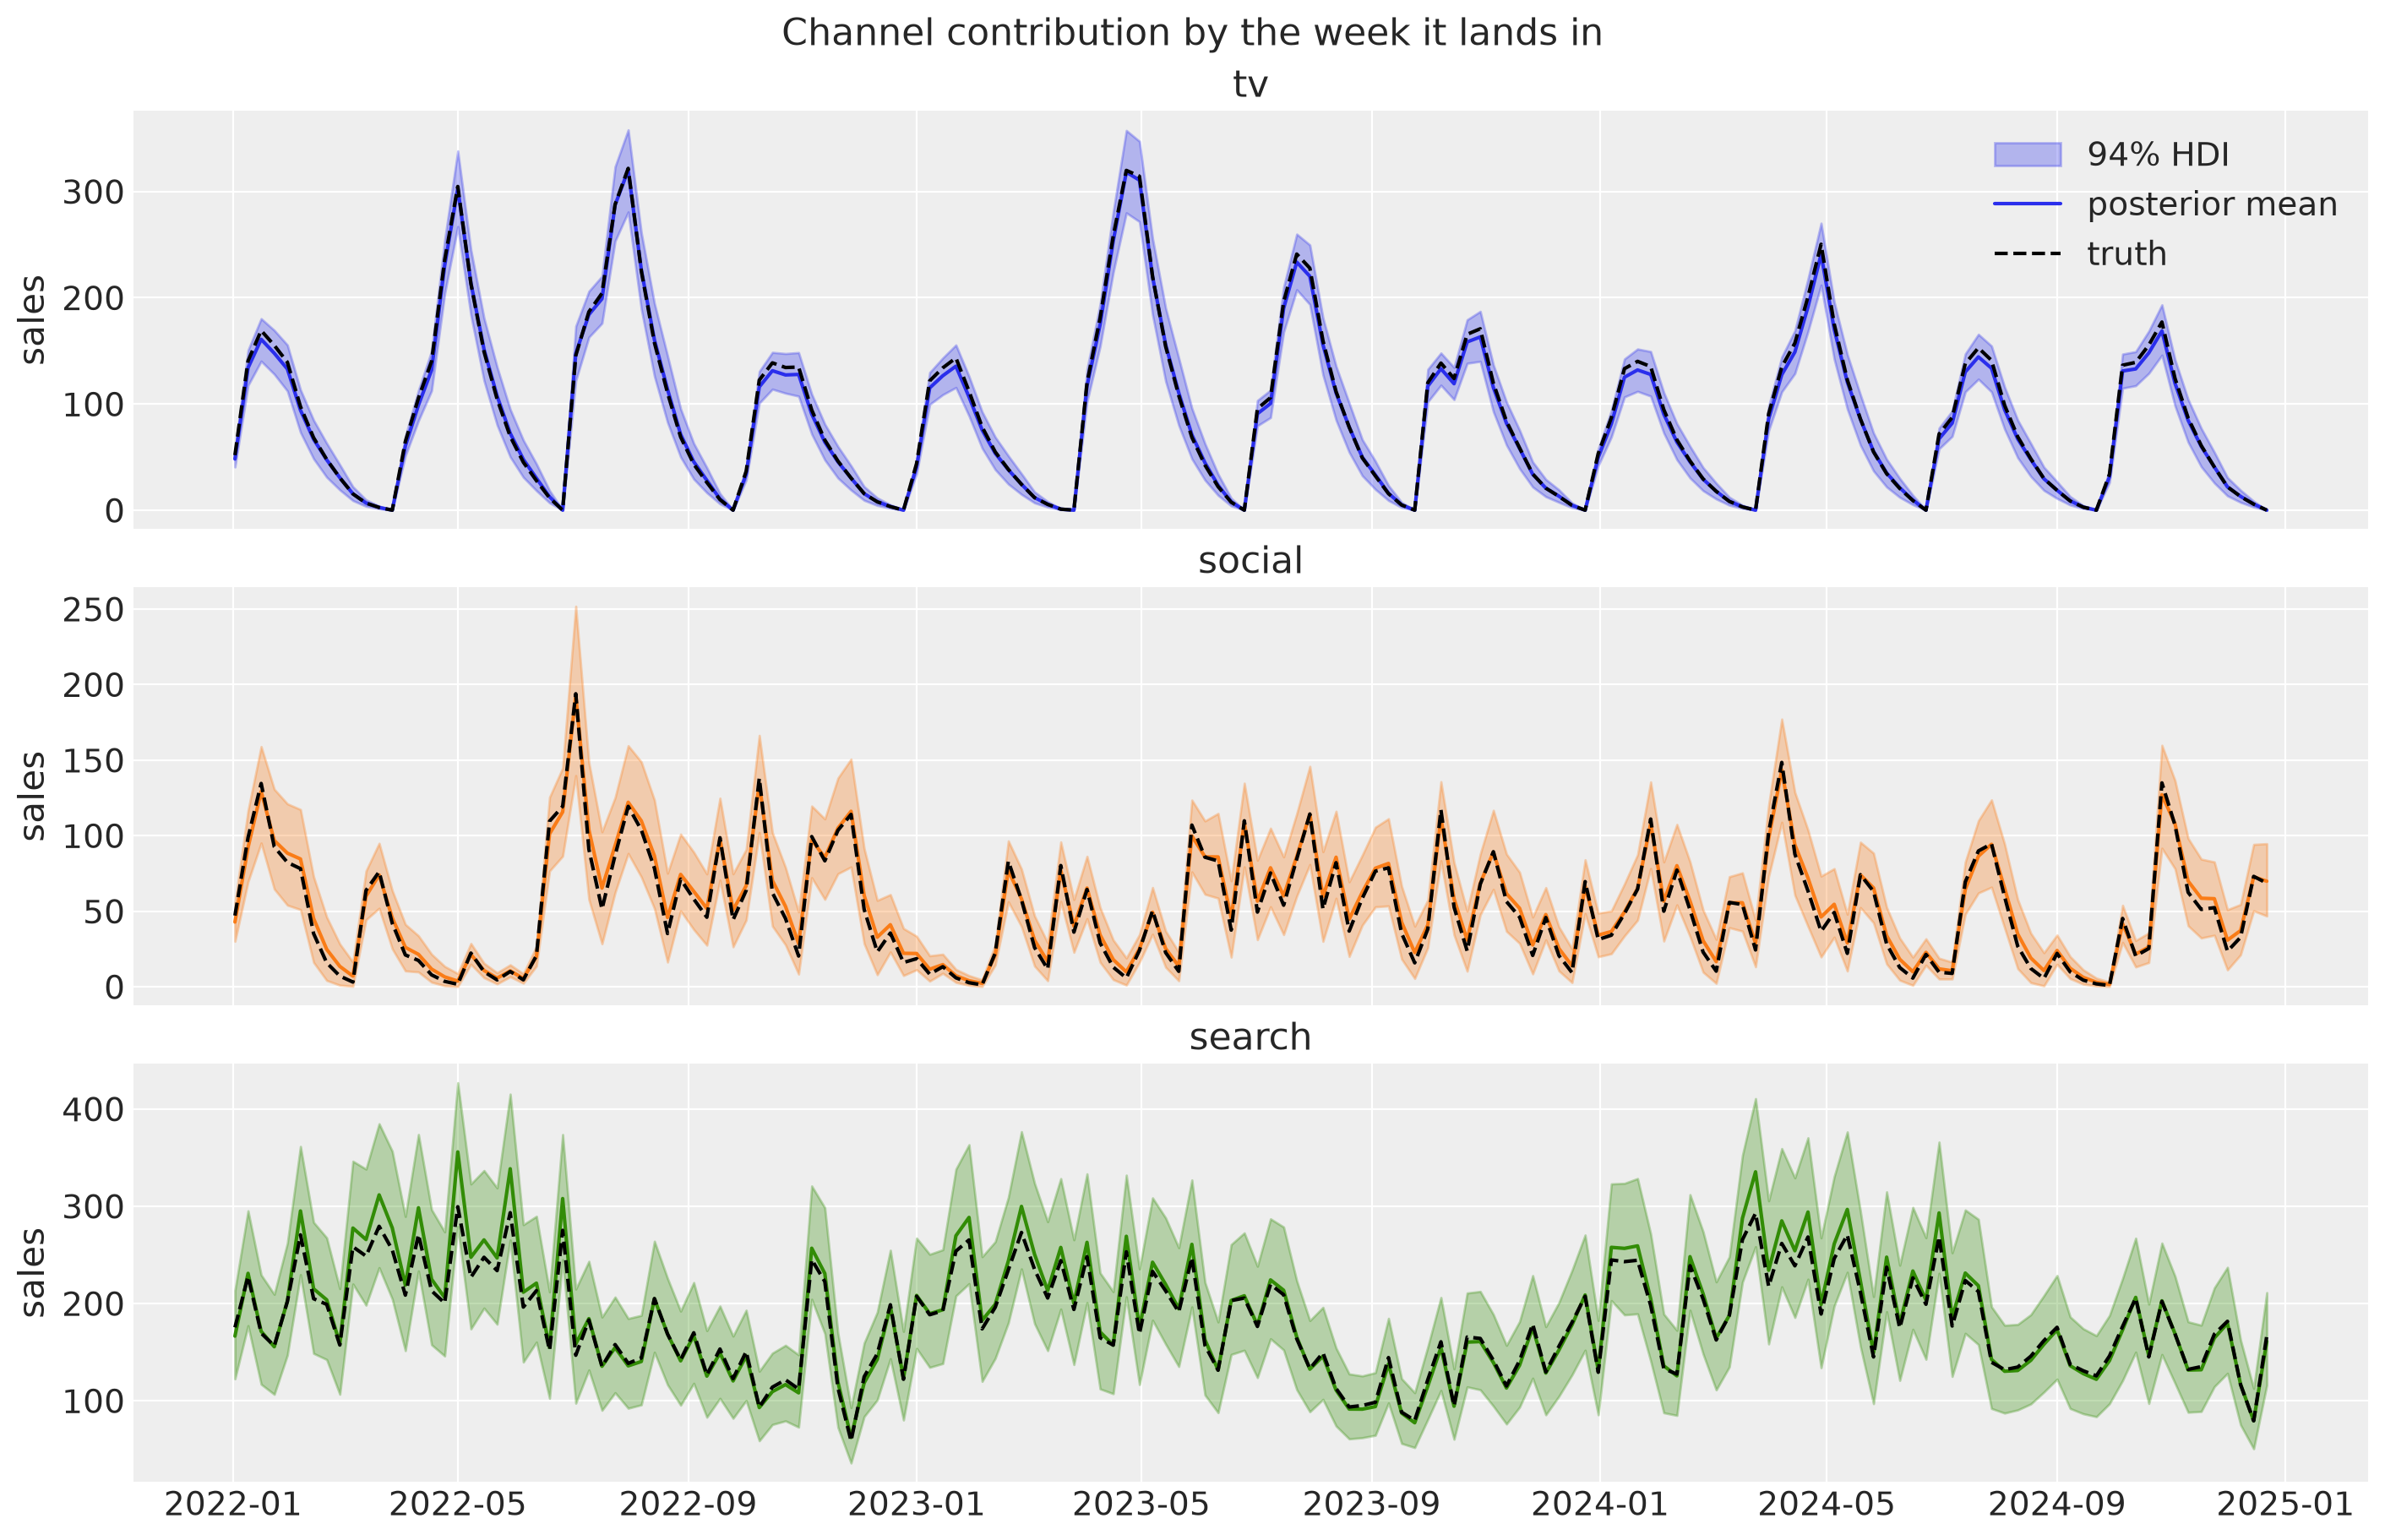

In [13]:
contribution = mmm.data.get_contributions(original_scale=True)["channels"]
contribution_hdi = az.hdi(contribution, prob=0.94)

fig, axes = plt.subplots(nrows=3, figsize=(14, 9), sharex=True, layout="constrained")
for ax, channel in zip(axes, channels, strict=True):
    i = channels.index(channel)
    interval = contribution_hdi.sel(channel=channel)
    ax.fill_between(
        dates,
        interval.sel(ci_bound="lower"),
        interval.sel(ci_bound="upper"),
        color=f"C{i}",
        alpha=0.3,
        label="94% HDI",
    )
    ax.plot(
        dates,
        contribution.sel(channel=channel).mean(("chain", "draw")),
        color=f"C{i}",
        label="posterior mean",
    )
    ax.plot(
        dates, true_contribution[channel], color="black", linestyle="--", label="truth"
    )
    ax.set(title=channel, ylabel="sales")
axes[0].legend(loc="upper right")
fig.suptitle("Channel contribution by the week it lands in", fontsize=16);

This is a **column** reading: everything that lands in week $t$, whichever week's spend caused it. A week of `tv` contribution includes carryover from several earlier flights.

The question a planner asks is the **row** reading: everything that one period's spend caused, whenever it lands. That is what {meth}`~pymc_marketing.mmm.incrementality.Incrementality.compute_incremental_contribution` returns. It zeroes the spend of one period at a time and records how much sales drop, over the period and the carryover window after it.

Let's compare the two readings on monthly periods.

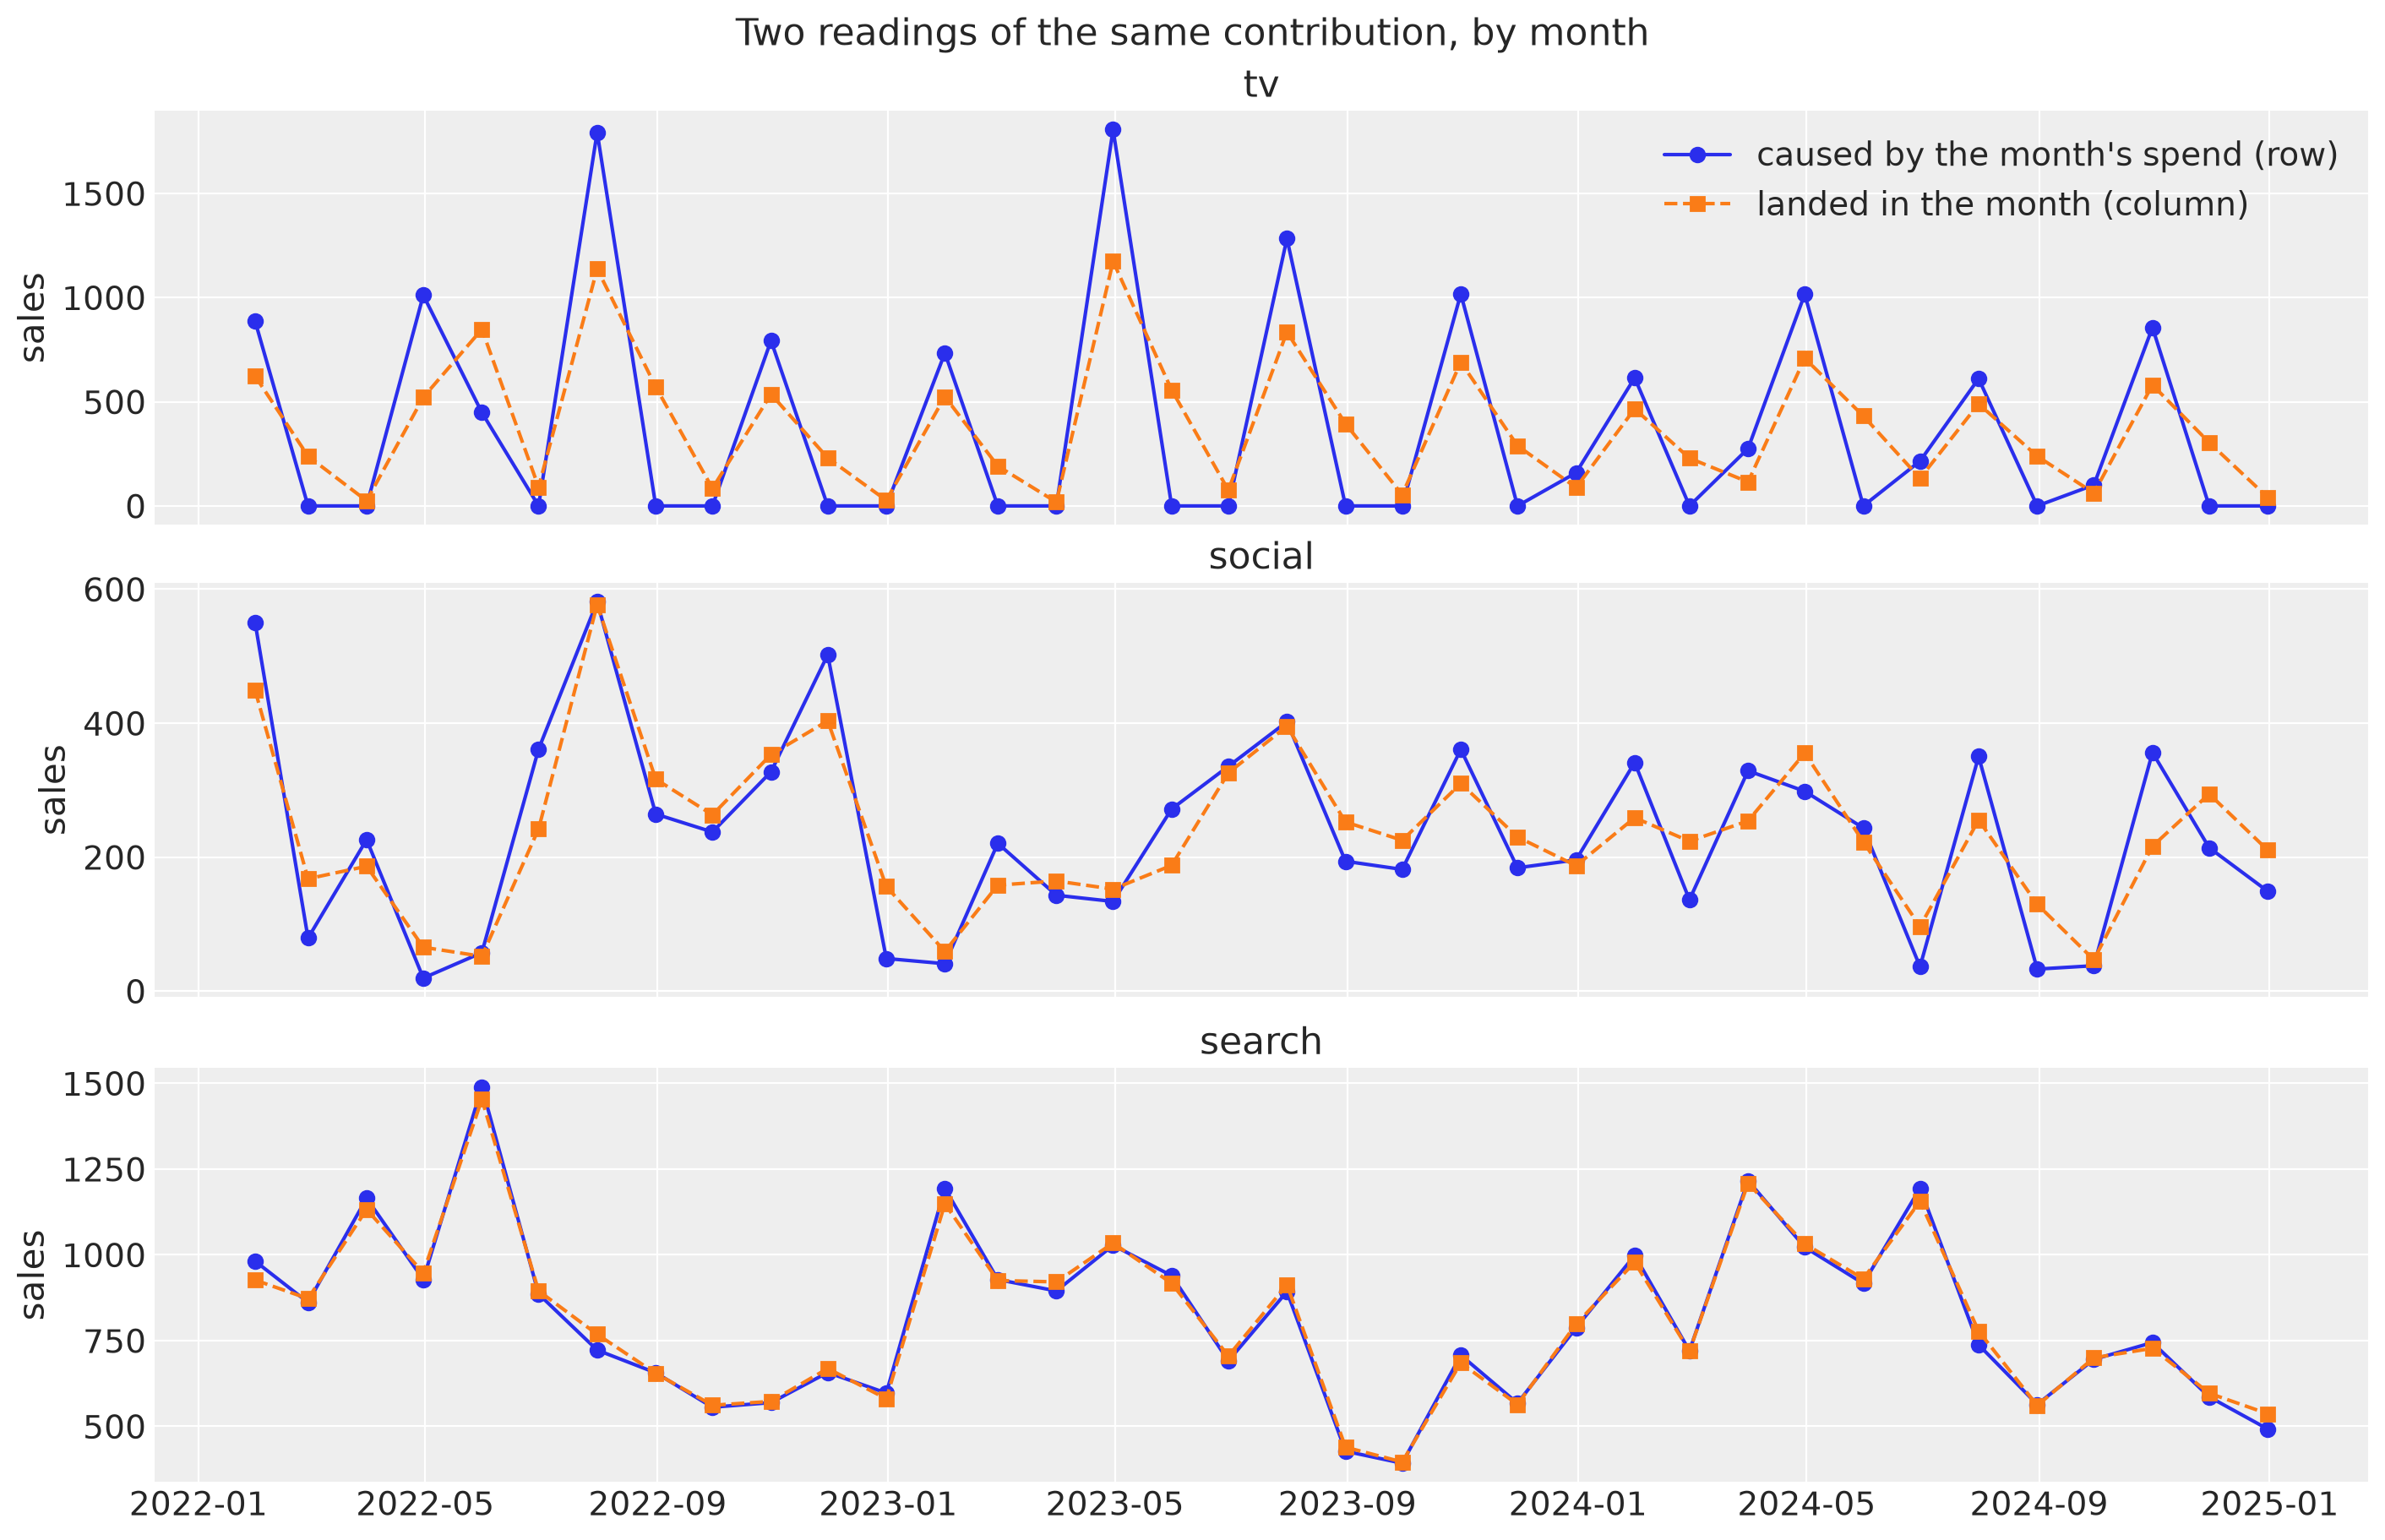

In [14]:
by_spend_month = mmm.incrementality.compute_incremental_contribution(
    frequency="monthly"
)
by_landing_month = contribution.resample(date="ME").sum()

fig, axes = plt.subplots(nrows=3, figsize=(14, 9), sharex=True, layout="constrained")
for ax, channel in zip(axes, channels, strict=True):
    rows = by_spend_month.sel(channel=channel).mean(("chain", "draw"))
    columns = by_landing_month.sel(channel=channel).mean(("chain", "draw"))
    ax.plot(rows["date"], rows, "o-", label="caused by the month's spend (row)")
    ax.plot(columns["date"], columns, "s--", label="landed in the month (column)")
    ax.set(title=channel, ylabel="sales")
axes[0].legend(loc="upper right")
fig.suptitle("Two readings of the same contribution, by month", fontsize=16);

For `search`, whose carryover fades within a week or two, the two readings almost coincide. For `tv` they differ a lot: a flight month causes more than lands in it, and the months after a flight receive value they did not pay for. The difference between the two lines is exactly the carryover we want to split out.

## The Carryover Matrix

Both readings are sums of one object. Let $A[s, u]$ be the part of channel $c$'s contribution that was caused by spend in period $s$ and lands on date $u$. Then

- the **row sum** $\sum_u A[s, u]$ is the value of period $s$'s spend (the row reading above), and
- the **column sum** $\sum_s A[s, u]$ is the contribution on date $u$ (the column reading).

{meth}`~pymc_marketing.mmm.incrementality.Incrementality.split_incremental_contribution_over_time` returns $A$ with the posterior intact. Rows are spend periods at the requested frequency (`spend_date` is the period end), and columns are the data's own dates.

We build it with `estimand="counterfactual"`, the default, which zeroes one period's spend at a time. The other estimand, the allocation, is compared with it in "The Default Order: Adstock First" below.

In [15]:
carryover = mmm.incrementality.split_incremental_contribution_over_time(
    frequency="monthly", estimand="counterfactual"
)
carryover

<xarray.DataArray (chain: 4, draw: 1000, spend_date: 36, realization_date: 163,
                   channel: 3)> Size: 563MB
array([[[[[ 52.61101685,  35.1608563 , 132.59630013],
          [146.8874583 ,  70.25653012, 183.64527292],
          [179.0209716 ,  93.16949369, 127.6499246 ],
          ...,
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ]],

         [[  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          ...,
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ]],

         [[  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          ...,
...
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ]],

         [[  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          ...,
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ]],

         [[  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          [  0.        ,   0.        ,   0.        ],
          ...,
          [         nan,          nan,          nan],
          [         nan,          nan,          nan],
          [         nan,          nan,          nan]]]]],
      shape=(4, 1000, 36, 163, 3))
Coordinates:
  * chain             (chain) int64 32B 0 1 2 3
  * draw              (draw) int64 8kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999
  * spend_date        (spend_date) datetime64[us] 288B 2022-01-31 ... 2024-12-31
    period_start      (spend_date) datetime64[us] 288B 2022-01-02 ... 2024-12-01
  * realization_date  (realization_date) datetime64[us] 1kB 2022-01-02 ... 20...
    observed          (spend_date, realization_date) bool 6kB True ... False
  * channel           (channel) <U6 72B 'tv' 'social' 'search'
Attributes:
    estimand:           counterfactual
    method:             pipeline
    effective_horizon:  7
    assumptions:        {"adstock_first": false, "normalize": true, "mode": "...
    warnings:           ["Some periods' carryover runs past the end of the fi...

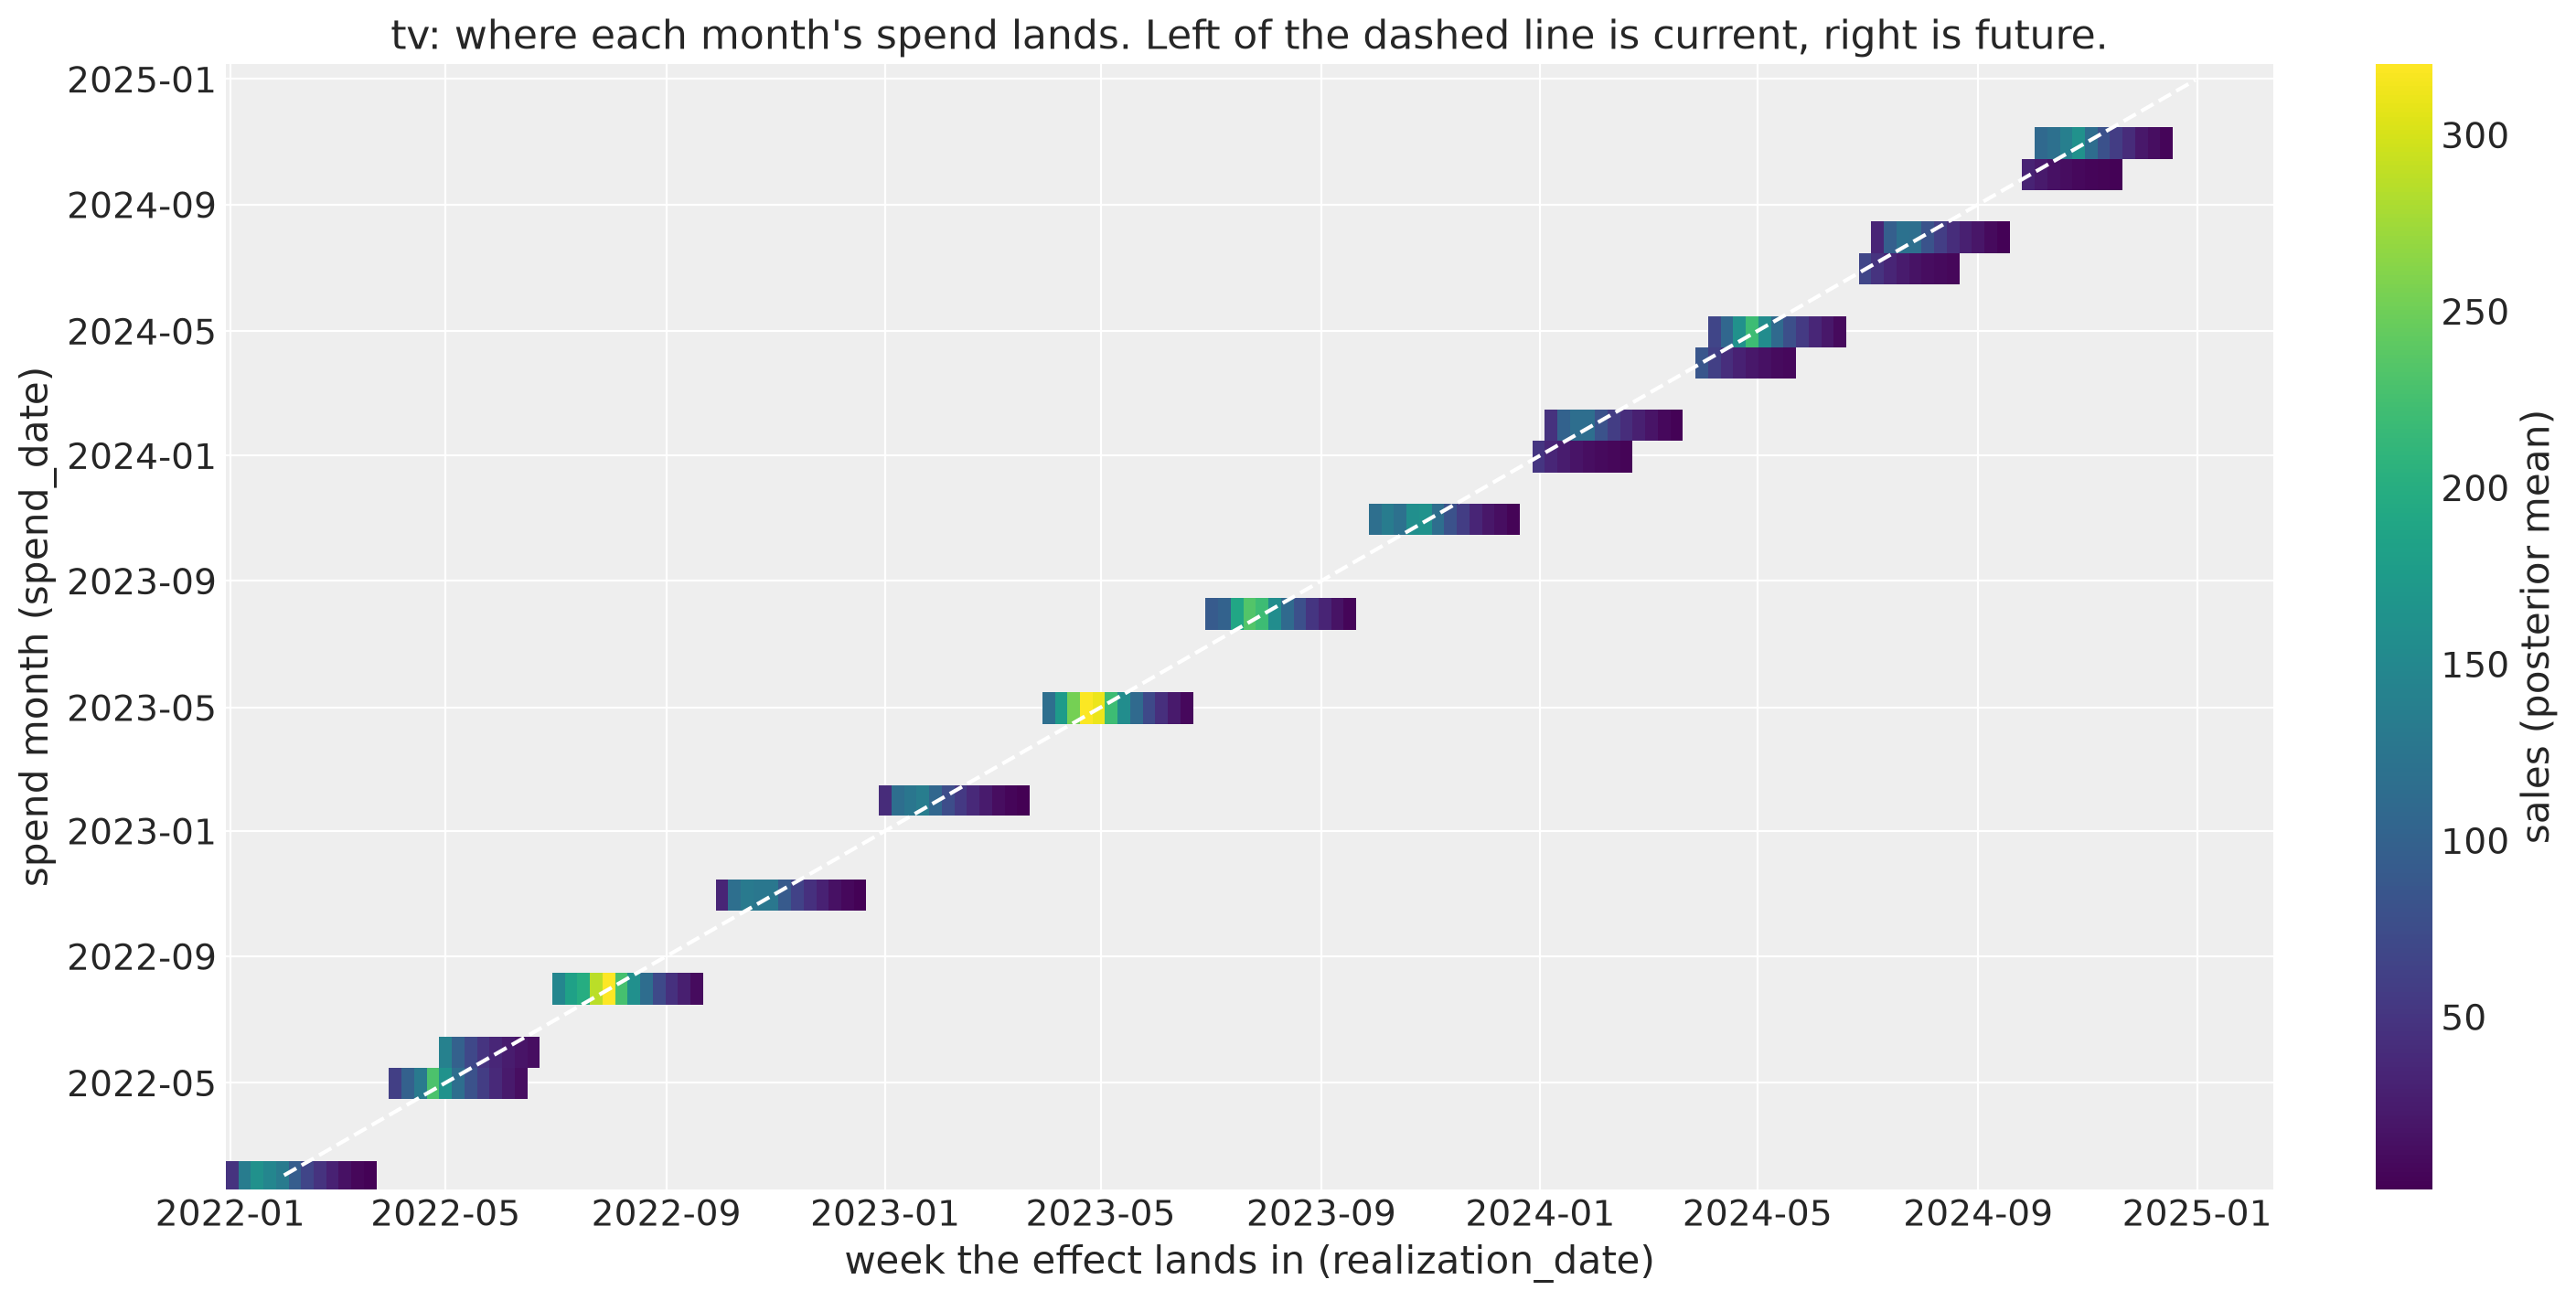

In [16]:
mean_tv = carryover.sel(channel="tv").mean(("chain", "draw"))

fig, ax = plt.subplots(figsize=(14, 7), layout="constrained")
mesh = ax.pcolormesh(
    mean_tv["realization_date"],
    mean_tv["spend_date"],
    mean_tv.where(mean_tv > 0),
    cmap="viridis",
    shading="nearest",
)
ax.plot(mean_tv["spend_date"], mean_tv["spend_date"], color="white", linestyle="--")
fig.colorbar(mesh, ax=ax, label="sales (posterior mean)")
ax.set(
    xlabel="week the effect lands in (realization_date)",
    ylabel="spend month (spend_date)",
    title="tv: where each month's spend lands. Left of the dashed line is current, right is future.",
);

Each row starts at the beginning of its month and fades over the following weeks. Flight months are bright, off months are empty. Everything left of the dashed diagonal lands in the spend month; everything right of it lands later.

Let's verify the two reconciliations. Rows must sum to {meth}`~pymc_marketing.mmm.incrementality.Incrementality.compute_incremental_contribution`, draw by draw.

In [17]:
order = ("chain", "draw", "spend_date", "channel")
rows = carryover.sum("realization_date").transpose(*order)
reference = by_spend_month.rename(date="spend_date").transpose(*order)
max_gap = float(np.abs(rows.values - reference.values).max())
print(f"max |row sum - incremental contribution| = {max_gap:.2e}")

max |row sum - incremental contribution| = 0.00e+00


The columns should sum to `channel_contribution`. Here we use `estimand="allocation"`, which keeps exactly the fitted dates as columns. Because the model applies saturation first, the allocation and the counterfactual matrix are the same numbers.

In [18]:
allocation = mmm.incrementality.split_incremental_contribution_over_time(
    frequency="monthly", estimand="allocation"
)
columns = allocation.sum("spend_date").rename(realization_date="date")
column_gap = float(abs(columns - contribution.transpose(*columns.dims)).max())
estimand_gap = float(
    abs(allocation - carryover.sel(realization_date=allocation.realization_date)).max()
)
print(f"max |column sum - channel_contribution|     = {column_gap:.2e}")
print(f"max |allocation - counterfactual matrix|    = {estimand_gap:.2e}")

max |column sum - channel_contribution|     = 3.98e-13
max |allocation - counterfactual matrix|    = 0.00e+00


One more detail of the matrix matters for the split. The last months' carryover runs past the end of the data. The matrix extends its columns to those dates, but the cells are `NaN` and marked `observed=False`: the model knows the effect is there, but the data cannot show it.

In [19]:
incomplete = carryover["spend_date"][~carryover["observed"].all("realization_date")]
past_data = carryover["realization_date"][carryover["realization_date"] > dates[-1]]
print("incomplete spend months: ", incomplete.dt.strftime("%Y-%m").values)
print("dates past the data:     ", past_data.dt.strftime("%Y-%m-%d").values)

incomplete spend months:  ['2024-11' '2024-12']
dates past the data:      ['2024-12-29' '2025-01-05' '2025-01-12' '2025-01-19' '2025-01-26'
 '2025-02-02' '2025-02-09']


## Current vs Future Value

With the matrix in hand, the split is a reduction of each row: **current** sums the dates inside the spend month, **future** sums the dates after it.
{meth}`~pymc_marketing.mmm.incrementality.Incrementality.split_incremental_contribution_current_future` does exactly that, one row at a time, without materializing the matrix.

We report monthly. The reporting period *is* the definition of current, and a month matches this kernel: `l_max=8` weeks of carryover often crosses a month boundary, so the split shows how the timing within the month matters. We come back to the choice of frequency below.

In [20]:
split = mmm.incrementality.split_incremental_contribution_current_future(
    frequency="monthly"
)
split

<xarray.Dataset> Size: 10MB
Dimensions:       (chain: 4, draw: 1000, channel: 3, spend_date: 36)
Coordinates:
  * chain         (chain) int64 32B 0 1 2 3
  * draw          (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * channel       (channel) <U6 72B 'tv' 'social' 'search'
  * spend_date    (spend_date) datetime64[us] 288B 2022-01-31 ... 2024-12-31
    period_start  (spend_date) datetime64[us] 288B 2022-01-02 ... 2024-12-01
    complete      (spend_date) bool 36B True True True True ... True False False
Data variables:
    current       (chain, draw, spend_date, channel) float64 3MB 698.3 ... nan
    future        (chain, draw, spend_date, channel) float64 3MB 319.5 ... nan
    future_share  (chain, draw, spend_date, channel) float64 3MB 0.3139 ... nan
Attributes:
    estimand:           counterfactual
    method:             pipeline
    effective_horizon:  7
    assumptions:        {"adstock_first": false, "normalize": true, "mode": "...
    warnings:           ["Some periods' carryover runs past the end of the fi...
    horizon:            0

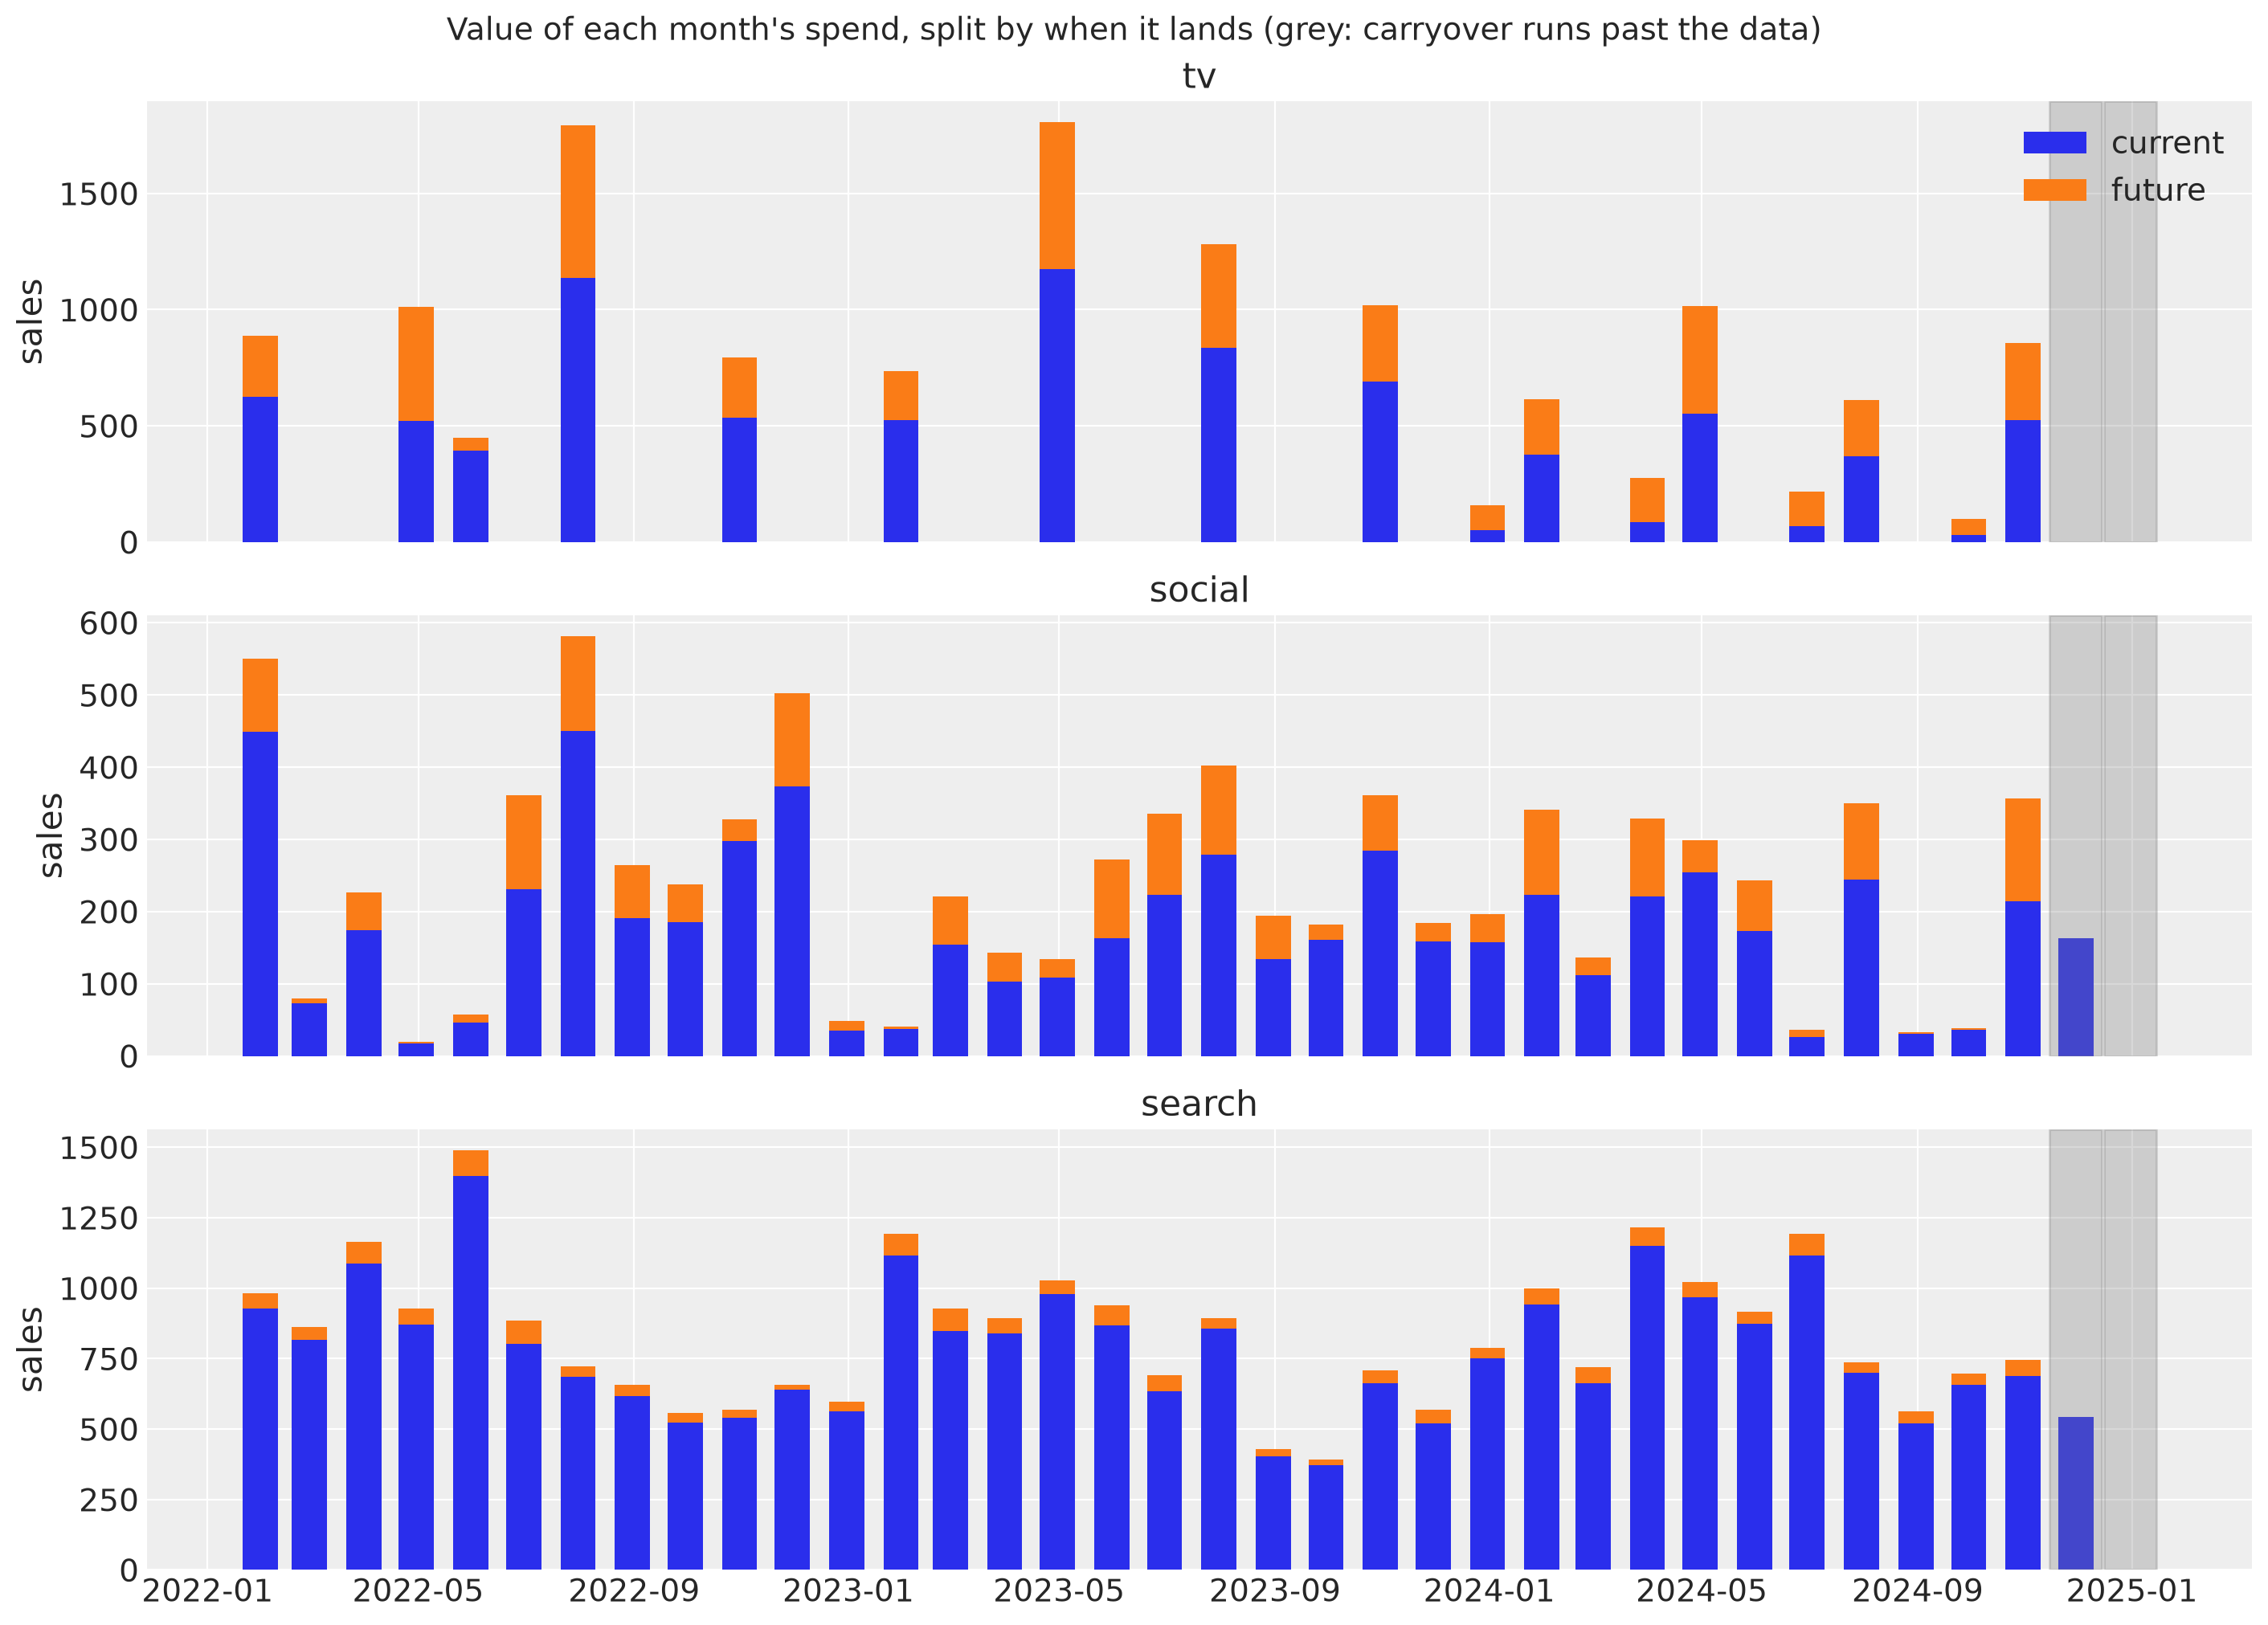

In [21]:
fig, axes = plt.subplots(nrows=3, figsize=(14, 10), sharex=True, layout="constrained")
# Pass the dates as a DatetimeIndex: with a DataArray, matplotlib mis-converts the bar width.
spend_months = split["spend_date"].to_index()
for ax, channel in zip(axes, channels, strict=True):
    current = split["current"].sel(channel=channel).mean(("chain", "draw")).to_numpy()
    future = split["future"].sel(channel=channel).mean(("chain", "draw")).to_numpy()
    ax.bar(spend_months, current, width=20, color="C0", label="current")
    ax.bar(
        spend_months,
        np.nan_to_num(future),
        bottom=np.nan_to_num(current),
        width=20,
        color="C1",
        label="future",
    )
    for month in spend_months[~split["complete"].to_numpy()]:
        ax.axvspan(
            month - pd.Timedelta(days=15),
            month + pd.Timedelta(days=15),
            color="grey",
            alpha=0.3,
        )
    ax.set(title=channel, ylabel="sales")
axes[0].legend(loc="upper right")
fig.suptitle(
    "Value of each month's spend, split by when it lands (grey: carryover runs past the data)",
    fontsize=14,
);

About a third of a `tv` month's value lands after the month, while `search` is almost all current. In the grey months the carryover runs past the data, so `future` is `NaN` and only the current part is drawn.

To get **one future share per channel**, sum future and total value over the months first, and divide afterwards. Averaging monthly shares would weight a quiet month like a busy one. We keep the complete months only, since `future` is `NaN` on the others, and we do it draw by draw so the posterior carries through.

In [22]:
complete = split.sel(spend_date=split["complete"])
future_share = complete["future"].sum("spend_date") / (
    complete["current"] + complete["future"]
).sum("spend_date")

How does that compare with the truth? We know the true saturated spend $V$ and the true kernels, so we can build the true carryover matrix and split it the same way.

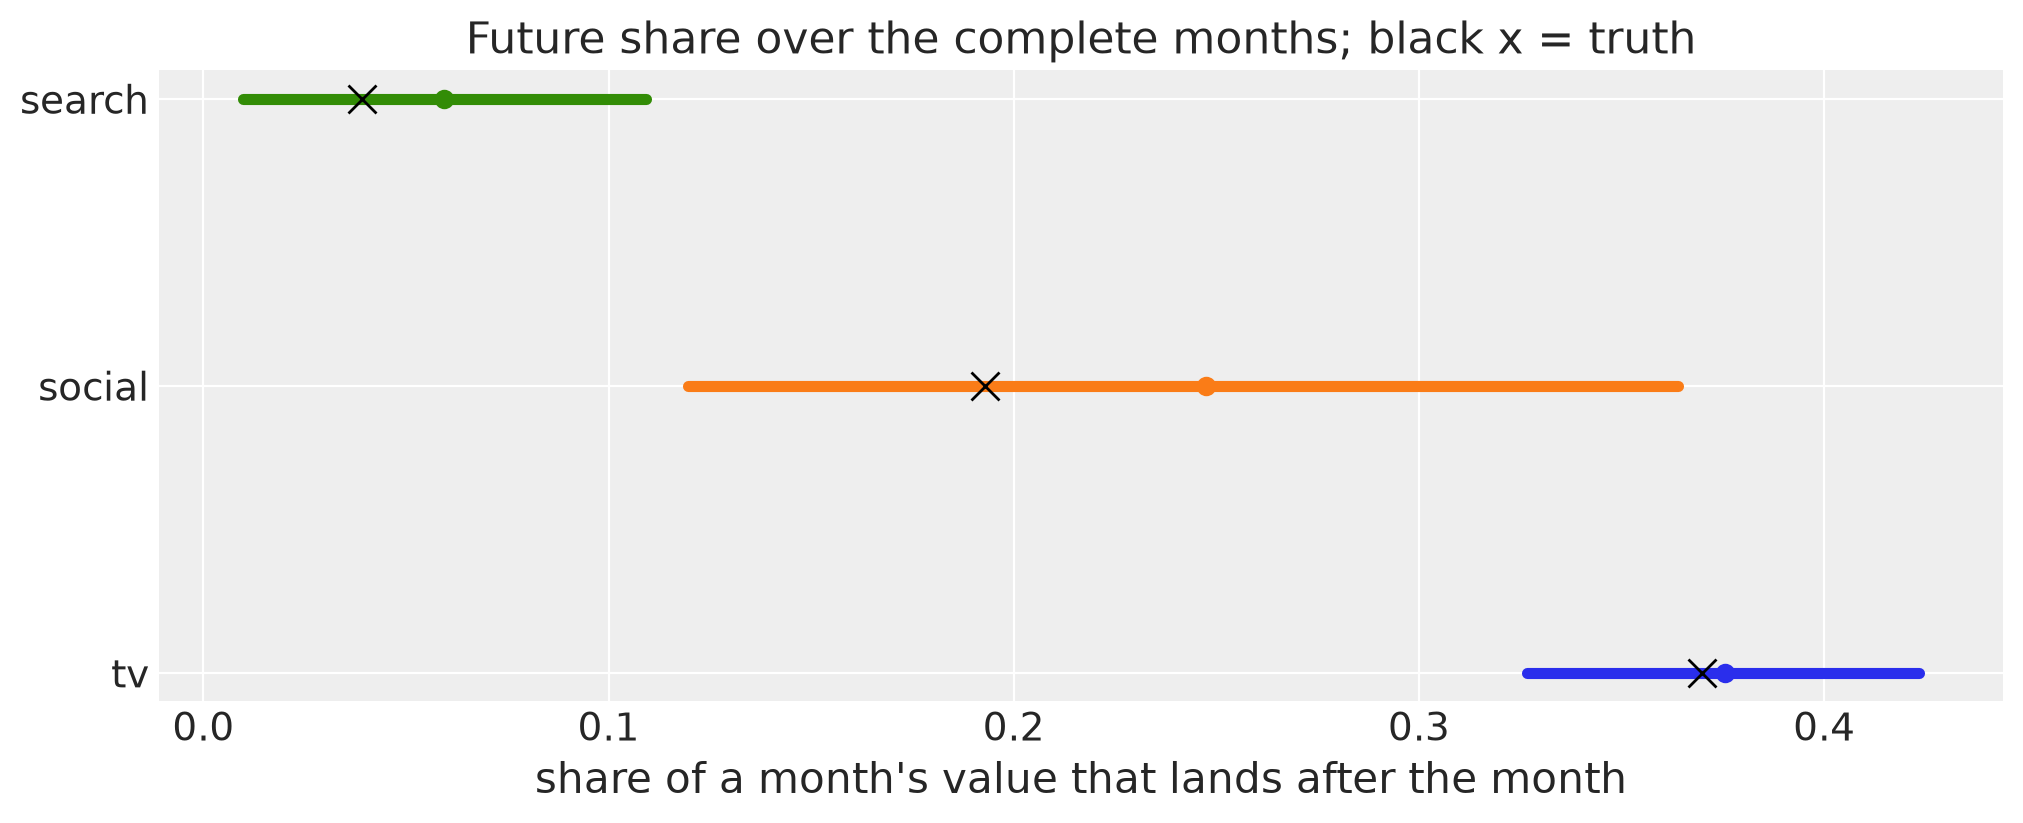

In [23]:
def true_monthly_split(channel: str) -> tuple[float, float]:
    # True current and future value over the complete months, from V and the true kernel.
    weights = true_kernel[channel]
    month = dates.to_period("M")
    complete_months = set(
        pd.DatetimeIndex(complete["spend_date"].values).to_period("M")
    )
    current = future = 0.0
    for s in range(n_weeks):
        if month[s] not in complete_months:
            continue
        for lag, weight in enumerate(weights):
            landing = dates[s] + pd.Timedelta(weeks=lag)
            value = true_saturated[channel].iloc[s] * weight
            if landing.to_period("M") == month[s]:
                current += value
            else:
                future += value
    return current, future


true_future_share = {}
for channel in channels:
    true_current, true_future = true_monthly_split(channel)
    true_future_share[channel] = true_future / (true_current + true_future)

share_hdi = az.hdi(future_share, prob=0.94)
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for i, channel in enumerate(channels):
    interval = share_hdi.sel(channel=channel)
    ax.plot(
        [float(interval.sel(ci_bound="lower")), float(interval.sel(ci_bound="upper"))],
        [i, i],
        color=f"C{i}",
        linewidth=4,
    )
    ax.plot(float(future_share.sel(channel=channel).mean()), i, "o", color=f"C{i}")
    ax.plot(true_future_share[channel], i, "x", color="black", markersize=10)
ax.set(
    yticks=range(len(channels)),
    yticklabels=channels,
    xlabel="share of a month's value that lands after the month",
    title="Future share over the complete months; black x = truth",
);

In [24]:
pd.DataFrame(
    {
        "posterior mean": future_share.mean(("chain", "draw")).to_series(),
        "94% HDI lower": share_hdi.sel(ci_bound="lower").to_series(),
        "94% HDI upper": share_hdi.sel(ci_bound="upper").to_series(),
        "truth": pd.Series(true_future_share),
    }
).round(3)

,posterior mean,94% HDI lower,94% HDI upper,truth
tv,0.376,0.327,0.424,0.370
social,0.247,0.120,0.364,0.193
search,0.059,0.010,0.109,0.039


### The Frequency Is the Definition of Current

A future share belongs to a channel *and* a reporting period. The same model and the same spend give different shares at different frequencies, because a longer period keeps more of the carryover inside it:

In [25]:
def future_share(split: xr.Dataset) -> xr.DataArray:
    complete = split.sel(spend_date=split["complete"])
    return complete["future"].sum("spend_date") / (
        complete["current"] + complete["future"]
    ).sum("spend_date")


pd.DataFrame(
    {
        label: future_share(
            mmm.incrementality.split_incremental_contribution_current_future(
                frequency=frequency
            )
        )
        .mean(("chain", "draw"))
        .to_series()
        for label, frequency in [
            ("weekly", "original"),
            ("monthly", "monthly"),
            ("quarterly", "quarterly"),
        ]
    }
).round(3)

,weekly,monthly,quarterly
channel,,,
tv,0.687,0.376,0.040
social,0.516,0.247,0.077
search,0.203,0.059,0.020


At the weekly frequency each week is its own period, so only the first kernel weight is current and the future share is $1 - C(0)$: most of `tv`'s value then counts as future. A quarter holds almost all of an eight-week kernel, so very little is left for the future. Neither number is more correct than the other. Always report the future share together with the period it refers to.

## A Fixed Window and the Cumulative Weights

Monthly reporting is one definition of "current". Media planning often prefers a fixed window instead: *what lands within $h$ weeks of the spend?* Pass `horizon` at the data's own frequency:

In [26]:
weekly = mmm.incrementality.split_incremental_contribution_current_future(
    frequency="original", horizon=1
)
weekly["current"].sel(channel="tv").mean(("chain", "draw")).to_series().head()

spend_date
2022-01-02     82.185909
2022-01-09    170.369331
2022-01-16    112.998554
2022-01-23     58.147999
2022-01-30     48.386868
Name: current, dtype: float64

With a fixed window the bookkeeping becomes very simple. When saturation comes first, week $s$'s spend is worth $V_s \sum_l w_l$ in total, and the part within $h$ weeks is $V_s \sum_{l \le h} w_l$. So the current share is

$$
C(h) = \frac{\sum_{l \le h} w_l}{\sum_{l < l_{\max}} w_l},
$$

one number per channel and posterior draw, the same for every week and every spend level. {meth}`~pymc_marketing.mmm.components.adstock.AdstockTransformation.cumulative_weights` returns it. Called without a `horizon`, it returns the whole curve.

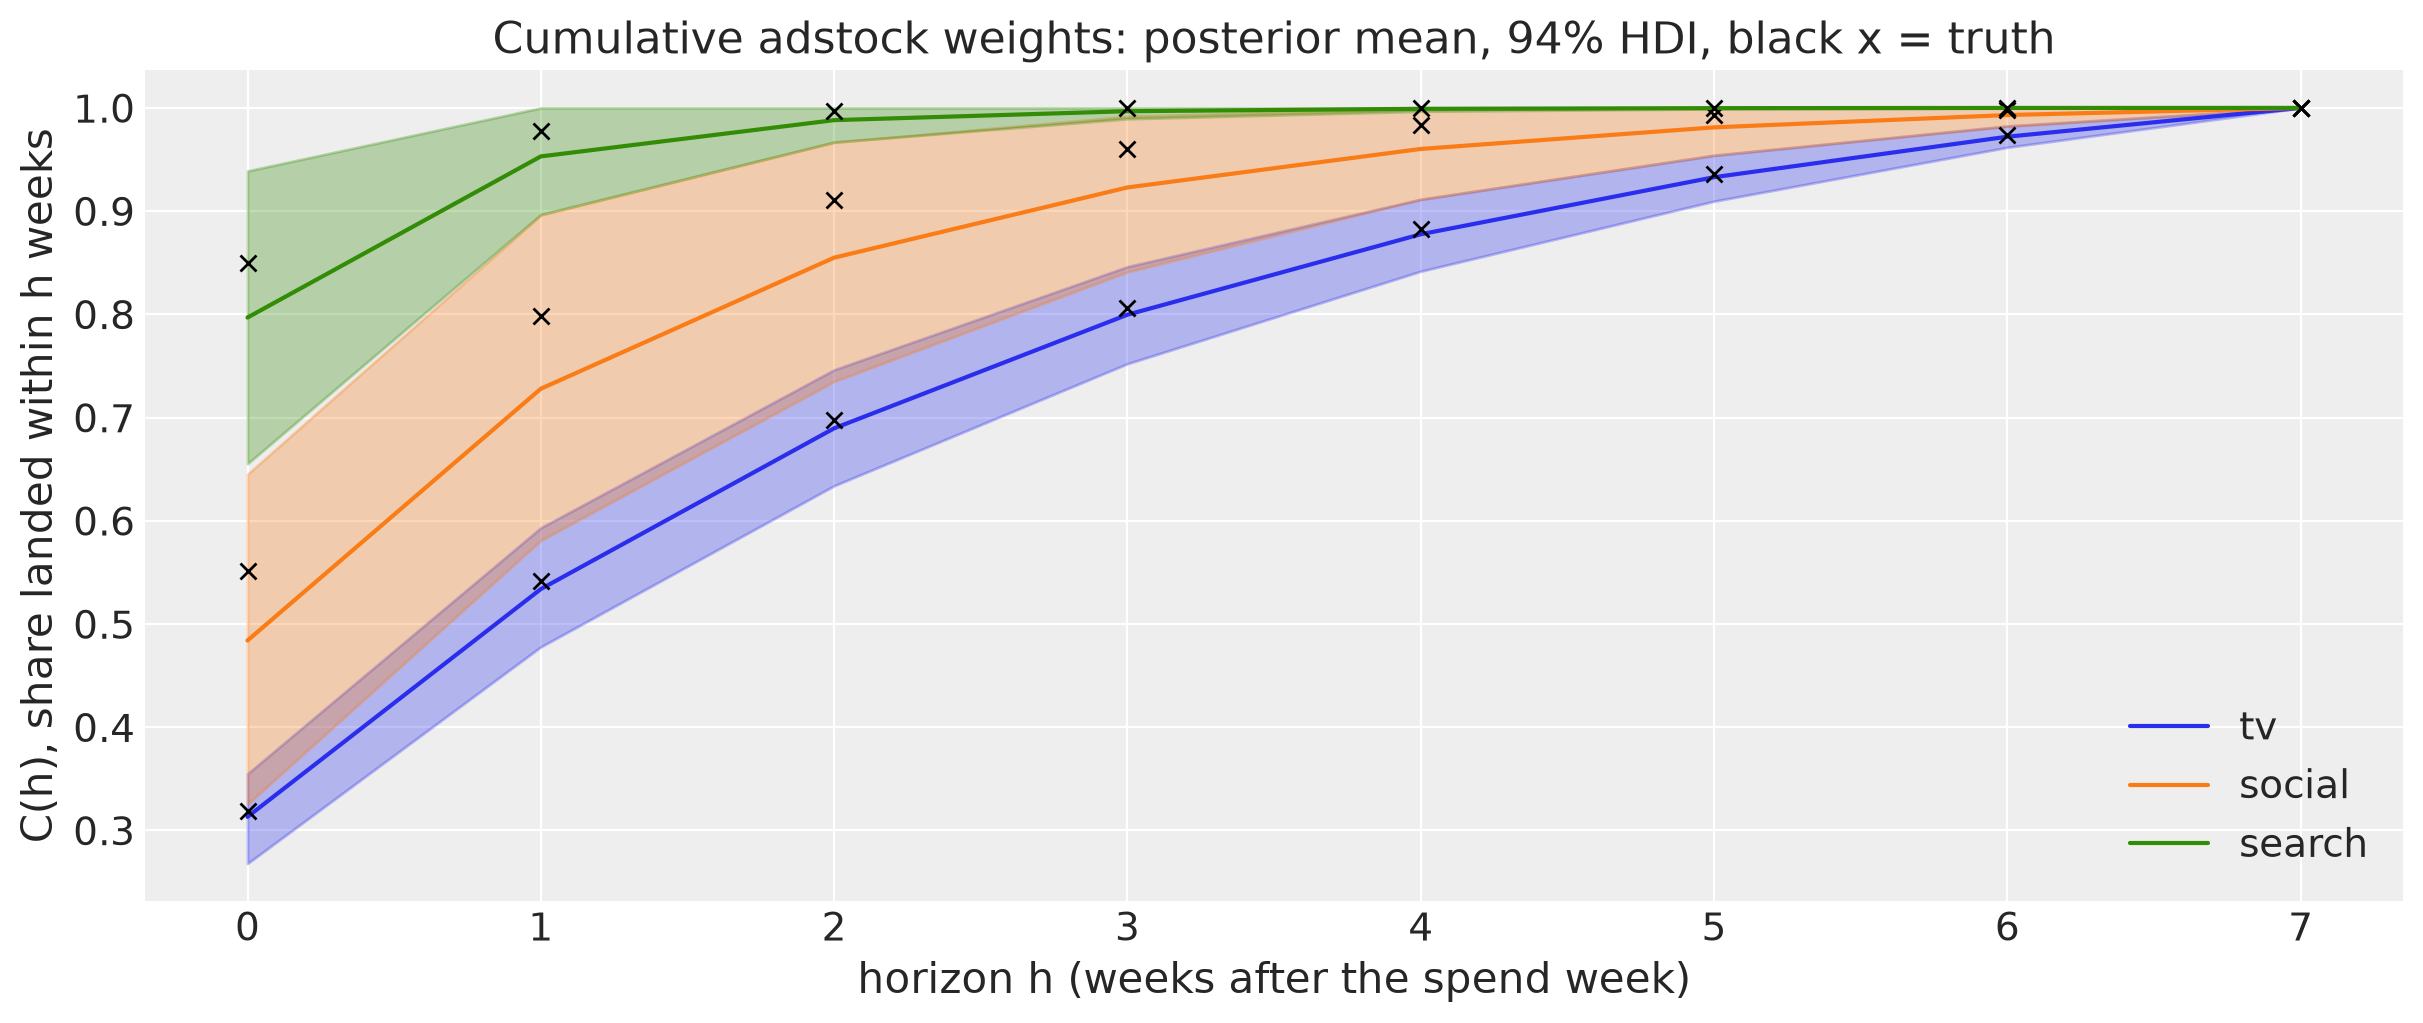

In [27]:
curve = mmm.adstock.cumulative_weights(
    mmm.idata.posterior.dataset[["adstock_alpha"]], progressbar=False
)
curve_hdi = az.hdi(curve, prob=0.94)

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
lags = curve["horizon"].values
for i, channel in enumerate(channels):
    interval = curve_hdi.sel(channel=channel)
    ax.fill_between(
        lags,
        interval.sel(ci_bound="lower"),
        interval.sel(ci_bound="upper"),
        color=f"C{i}",
        alpha=0.3,
    )
    ax.plot(
        lags,
        curve.sel(channel=channel).mean(("chain", "draw")),
        color=f"C{i}",
        label=channel,
    )
    ax.plot(lags, np.cumsum(true_kernel[channel]), "x", color="black")
ax.set(
    xlabel="horizon h (weeks after the spend week)",
    ylabel="C(h), share landed within h weeks",
    title="Cumulative adstock weights: posterior mean, 94% HDI, black x = truth",
)
ax.legend();

The current value of a complete week is $C(h)$ times that week's total value, draw by draw. Let's check it on `horizon=1`:

In [28]:
c1 = curve.sel(horizon=1, drop=True)
complete_weeks = weekly.sel(spend_date=weekly["complete"])
total = complete_weeks["current"] + complete_weeks["future"]
gap = float(abs(complete_weeks["current"] - c1 * total).max())
print(f"max |current - C(1) * total| over the complete weeks = {gap:.2e}")

max |current - C(1) * total| over the complete weeks = 2.27e-13


```{important}
Multiply $C(h)$ by the value **per draw** and summarize last. $C(h)$ and the value come from the same posterior draws, so the product of their means is not the mean of their product.
```

## The Closed Form

Everything so far used the default `method="pipeline"`: the model is evaluated once per spend period with that period's spend set to zero. That is exact for every supported model, including `adstock_first=True`, log links and mediated effects.

For a model like ours there is a shortcut. The matrix is $A[s, s+l] = w_l V_s$: the kernel times how much week $s$'s saturated spend changes between the actual and the counterfactual spend,

$$
V_s = \beta\, g(x_s) - \beta\, g(f\, x_s),
$$

where $f$ is `counterfactual_spend_factor`. With the default $f = 0$ that is the saturated spend less its value at zero spend. Our logistic saturation is zero at zero spend, so here it is exactly the $V_s$ of the data generating process.

`method="closed_form"` reads both pieces off the posterior. It evaluates the saturation once for all weeks, at both spend levels, instead of simulating each period. For the current/future split it reads the cumulative weights off the same kernel and never builds the matrix.

In [29]:
timings = {}
results = {}
for method in ["pipeline", "closed_form"]:
    start = time.perf_counter()
    results[method] = mmm.incrementality.split_incremental_contribution_current_future(
        frequency="original", horizon=1, method=method
    )
    timings[method] = time.perf_counter() - start

for name in ["current", "future"]:
    difference = abs(results["closed_form"][name] - results["pipeline"][name])
    print(f"max |closed form - pipeline| for {name}: {float(difference.max()):.2e}")
print({method: f"{seconds:.2f}s" for method, seconds in timings.items()})

max |closed form - pipeline| for current: 5.12e-13
max |closed form - pipeline| for future: 2.84e-13
{'pipeline': '1.46s', 'closed_form': '0.30s'}


The two methods return the same numbers, `NaN` for `NaN`. The closed form is faster when there are many periods, as here with weekly rows. At coarse frequencies such as quarters there are few periods to simulate, and the two cost about the same.

The closed form is only exact when the model is additively separable across spend periods, so it raises on any other model. It requires `adstock_first=False`, an identity link, one of the library's adstocks with `ConvMode.After`, no `time_varying_media` and no channel-dependent `mu_effects`. Before reading the closed form, it also asks the spend probe whether the media transform carries spend over a window or mixes channels, and whether the effect of spend dies out within the fitted dates. Carryover longer than the data fails that last check: the pipeline still evaluates such a model, the closed form refuses it.

The counterfactual does not have to be zero spend. Because the closed form evaluates the saturation at both spend levels, it answers *what if each period's spend had been 10% lower?* exactly too:

In [30]:
lower_spend = {
    method: mmm.incrementality.split_incremental_contribution_current_future(
        frequency="monthly", method=method, counterfactual_spend_factor=0.9
    )
    for method in ["pipeline", "closed_form"]
}

for name in ["current", "future"]:
    difference = abs(lower_spend["closed_form"][name] - lower_spend["pipeline"][name])
    print(f"max |closed form - pipeline| for {name}: {float(difference.max()):.2e}")

max |closed form - pipeline| for current: 9.66e-13
max |closed form - pipeline| for future: 2.95e-13


The allocation is the exception. It splits each date's contribution against zero spend whichever method computes it, so a different spend level is refused:

In [31]:
try:
    mmm.incrementality.split_incremental_contribution_over_time(
        frequency="monthly",
        estimand="allocation",
        method="closed_form",
        counterfactual_spend_factor=0.9,
    )
except ValueError as error:
    print(f"ValueError: {error}")

ValueError: estimand='allocation' splits the contribution against zero spend, so counterfactual_spend_factor must be 0, got 0.9.


## The Default Order: Adstock First

So far the model applied saturation before the adstock, the case where everything lines up. `MMM`'s default is the other order, `adstock_first=True`: the adstock first sums each week's carryover from earlier spend, and the saturation then acts on that sum,

$$
\text{contribution}_t = \beta\, g\Big(\sum_{l} w_l\, x_{t-l}\Big).
$$

The saturation now sees every cohort at once, so what one week's spend adds depends on the other weeks' spend. The model is no longer additively separable, and the two ways of attributing a date's contribution to the spend behind it give different numbers:

- `estimand="counterfactual"` (the default) zeroes one period's spend and records what drops. Its rows reconcile with `compute_incremental_contribution`; its columns do not add up to `channel_contribution`.
- `estimand="allocation"` splits each date's `channel_contribution` among the cohorts in proportion to their part of the adstocked spend, an Aumann-Shapley split. Its columns reconcile with `channel_contribution`; its rows do not add up to the incremental contribution.

To see how much this matters on real data, we refit the model of the {ref}`mmm_case_study` on its weekly sales data, with its default transformation order, its priors and its holiday controls. This time there is no known truth, so instead of checking recovery we compare the two estimands.

In [32]:
raw_df = pd.read_csv(data_dir / "case_study_data.csv")

case_channel_mapping = {
    "mdsp_dm": "Direct Mail",
    "mdsp_inst": "Insert",
    "mdsp_nsp": "Newspaper",
    "mdsp_audtr": "Radio",
    "mdsp_vidtr": "TV",
    "mdsp_so": "Social Media",
    "mdsp_on": "Online Display",
}
case_channels = sorted(case_channel_mapping.values())
case_controls = [column for column in raw_df.columns if "hldy_" in column]

case_df = raw_df[["wk_strt_dt", "sales", *case_channel_mapping, *case_controls]].rename(
    columns=case_channel_mapping
)
case_df["wk_strt_dt"] = pd.to_datetime(case_df["wk_strt_dt"])
case_X = case_df.drop(columns="sales")
case_y = case_df["sales"]

print(
    f"{len(case_df)} weeks, {case_df['wk_strt_dt'].min():%Y-%m-%d} to {case_df['wk_strt_dt'].max():%Y-%m-%d}"
)

209 weeks, 2014-08-03 to 2018-07-29


We use the case study's model as it is: spend shares as the scale of the $\beta$ priors, a `GeometricAdstock` with `l_max=6`, a `LogisticSaturation` and five yearly Fourier modes. We fit it on all the data, and sample a little longer than the case study, with `target_accept=0.95`, so that every $\hat{R}$ stays below 1.01.

In [33]:
spend_shares = (
    case_X[case_channels].sum() / case_X[case_channels].sum().sum()
).sort_index()

case_mmm = MMM(
    model_config={
        "intercept": Prior("Normal", mu=0.2, sigma=0.05),
        "saturation_beta": Prior(
            "HalfNormal",
            sigma=xr.DataArray(spend_shares.to_numpy(), dims="channel"),
            dims="channel",
        ),
        "gamma_control": Prior("Normal", mu=0, sigma=1, dims="control"),
        "gamma_fourier": Prior("Laplace", mu=0, b=1, dims="fourier_mode"),
        "likelihood": Prior(
            "TruncatedNormal", lower=0, sigma=Prior("HalfNormal", sigma=1)
        ),
    },
    target_column="sales",
    date_column="wk_strt_dt",
    adstock=GeometricAdstock(l_max=6),
    saturation=LogisticSaturation(),
    channel_columns=case_channels,
    control_columns=case_controls,
    yearly_seasonality=5,
)
case_mmm.fit(
    X=case_X,
    y=case_y,
    target_accept=0.95,
    chains=6,
    draws=1_500,
    tune=2_000,
    nuts_sampler="nutpie",
    random_seed=rng,
)

case_var_names = [
    "intercept_contribution",
    "y_sigma",
    "saturation_beta",
    "saturation_lam",
    "adstock_alpha",
    "gamma_control",
    "gamma_fourier",
]
case_sampled = case_mmm.idata.posterior.dataset[case_var_names]
case_r_hat = az.rhat(case_sampled)
case_ess = az.ess(case_sampled, method="bulk")
print(f"divergences:  {case_mmm.idata['sample_stats']['diverging'].sum().item()}")
print(f"max r_hat:    {max(float(case_r_hat[v].max()) for v in case_var_names):.4f}")
print(f"min ess_bulk: {min(float(case_ess[v].min()) for v in case_var_names):.0f}")

NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


Output()

Output()

divergences:  0
max r_hat:    1.0057
min ess_bulk: 1251


The case study covers this model's fit and diagnostics in full, so we go straight to the split.

With 9,000 posterior draws and seven channels, a monthly carryover matrix holds about 5.2 GB per estimand. We work on a subsample of 1,000 draws instead. An integer `random_state` picks the same draws in every call, so all the objects below are computed on the same draws, and we subsample `channel_contribution` the same way to compare with them.

In [34]:
subsample = {"num_samples": 1_000, "random_state": seed}
incrementality = case_mmm.incrementality

case_counterfactual = incrementality.split_incremental_contribution_over_time(
    frequency="monthly", **subsample
)
case_allocation = incrementality.split_incremental_contribution_over_time(
    frequency="monthly", estimand="allocation", **subsample
)
case_rows = incrementality.compute_incremental_contribution(
    frequency="monthly", **subsample
)
case_contribution = subsample_draws(
    case_mmm.data.get_contributions(original_scale=True)[["channels"]], **subsample
)["channels"]

Each estimand reconciles with the quantity it is defined against, and not with the other one:

In [35]:
order = ("chain", "draw", "spend_date", "channel")
counterfactual_rows = case_counterfactual.sum("realization_date").transpose(*order)
reference_rows = case_rows.rename(date="spend_date").transpose(*order)

allocation_columns = (
    case_allocation.sum("spend_date")
    .rename(realization_date="date")
    .transpose(*case_contribution.dims)
)
counterfactual_columns = (
    case_counterfactual.sel(realization_date=case_allocation["realization_date"])
    .sum("spend_date")
    .rename(realization_date="date")
    .transpose(*case_contribution.dims)
)


def relative_gap(a: np.ndarray, b: np.ndarray) -> float:
    return float(np.abs(a - b).max() / np.abs(b).max())


print("counterfactual rows    vs incremental contribution:", end=" ")
print(f"{relative_gap(counterfactual_rows.values, reference_rows.values):.1e}")
print("allocation columns     vs channel_contribution:    ", end=" ")
print(f"{relative_gap(allocation_columns.values, case_contribution.values):.1e}")
print("counterfactual columns vs channel_contribution, total:", end=" ")
print(f"{float(counterfactual_columns.sum() / case_contribution.sum() - 1):+.1%}")
print("allocation rows        vs incremental contribution, total:", end=" ")
print(f"{float(case_allocation.sum() / case_rows.sum() - 1):+.1%}")

counterfactual rows    vs incremental contribution: 0.0e+00
allocation columns     vs channel_contribution:     4.2e-16
counterfactual columns vs channel_contribution, total: -1.4%
allocation rows        vs incremental contribution, total: +1.5%


The first two hold to rounding error. The last two show the cost of choosing: on this model, the counterfactual columns and the allocation rows miss the other quantity by a percent or two in total.

Now the current/future split under each estimand. For the counterfactual it is {meth}`~pymc_marketing.mmm.incrementality.Incrementality.split_incremental_contribution_current_future`. For the allocation we reduce the matrix ourselves, with the same definition of current: the dates from the start of the spend month to its end. As before, we keep the complete months and sum before dividing, draw by draw.

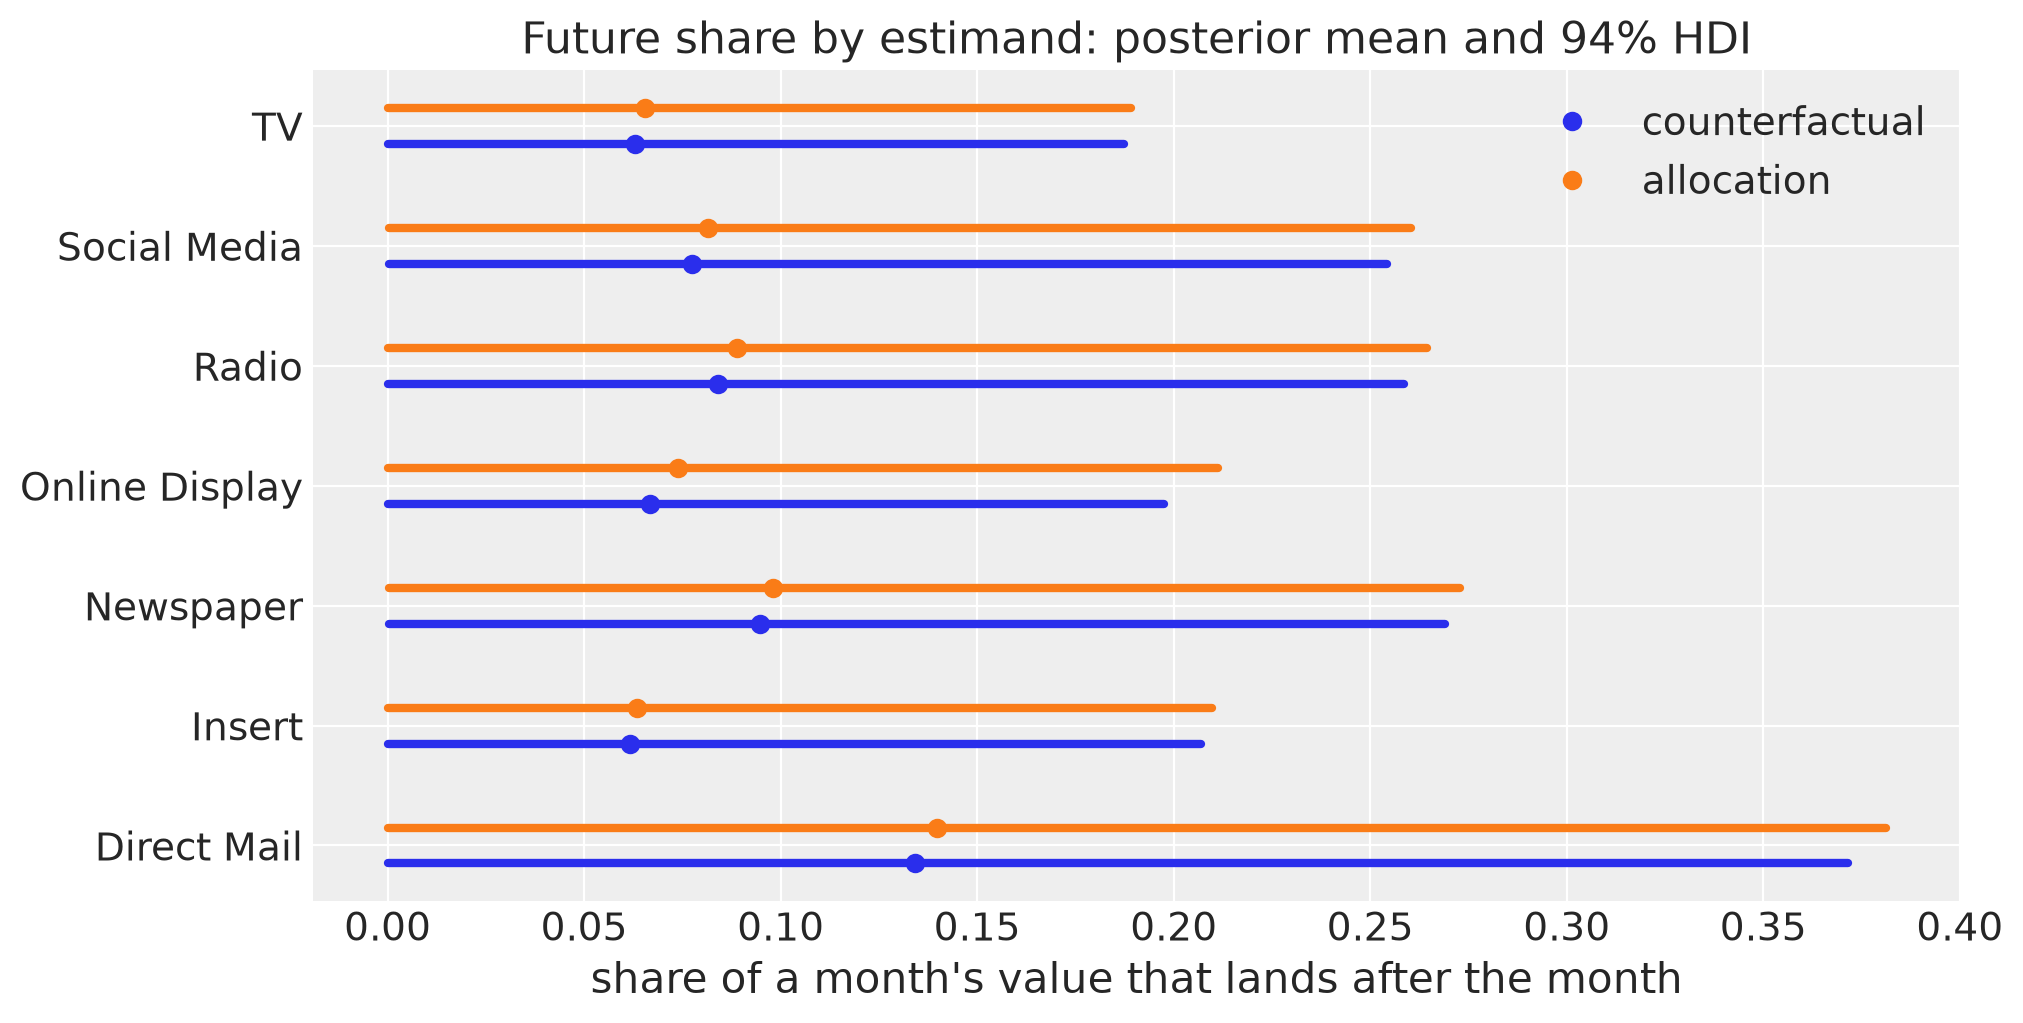

In [36]:
case_split = incrementality.split_incremental_contribution_current_future(
    frequency="monthly", **subsample
)
complete_months = case_split.sel(spend_date=case_split["complete"])
counterfactual_share = complete_months["future"].sum("spend_date") / (
    complete_months["current"] + complete_months["future"]
).sum("spend_date")

landing = pd.DatetimeIndex(case_allocation["realization_date"].values)
in_spend_month = xr.DataArray(
    (landing.values >= case_allocation["period_start"].values[:, None])
    & (landing.values <= case_allocation["spend_date"].values[:, None]),
    dims=("spend_date", "realization_date"),
    coords={
        "spend_date": case_allocation["spend_date"],
        "realization_date": case_allocation["realization_date"],
    },
)
allocation_complete = case_allocation.sel(spend_date=case_allocation["complete"])
allocation_total = allocation_complete.sum(("spend_date", "realization_date"))
allocation_current = allocation_complete.where(
    in_spend_month.sel(spend_date=allocation_complete["spend_date"]), 0.0
).sum(("spend_date", "realization_date"))
allocation_share = (allocation_total - allocation_current) / allocation_total

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for offset, (label, share, color) in zip(
    [-0.15, 0.15],
    [
        ("counterfactual", counterfactual_share, "C0"),
        ("allocation", allocation_share, "C1"),
    ],
    strict=True,
):
    interval = az.hdi(share, prob=0.94)
    for i, channel in enumerate(case_channels):
        ax.plot(
            [
                float(interval.sel(channel=channel, ci_bound="lower")),
                float(interval.sel(channel=channel, ci_bound="upper")),
            ],
            [i + offset, i + offset],
            color=color,
            linewidth=3,
        )
        ax.plot(
            float(share.sel(channel=channel).mean()),
            i + offset,
            "o",
            color=color,
            label=label if i == 0 else None,
        )
ax.set(
    yticks=range(len(case_channels)),
    yticklabels=case_channels,
    xlabel="share of a month's value that lands after the month",
    title="Future share by estimand: posterior mean and 94% HDI",
)
ax.legend();

In [37]:
pd.DataFrame(
    {
        "counterfactual": counterfactual_share.mean(("chain", "draw")).to_series(),
        "allocation": allocation_share.mean(("chain", "draw")).to_series(),
    }
).round(3)

,counterfactual,allocation
channel,,
Direct Mail,0.134,0.140
Insert,0.062,0.063
Newspaper,0.095,0.098
Online Display,0.067,0.074
Radio,0.084,0.089
Social Media,0.077,0.082
TV,0.063,0.066


On this model the two estimands tell the same story: every channel lands mostly in its own month, `Direct Mail` has the largest future share by posterior mean, and the allocation puts a slightly larger share in the future than the counterfactual. The gap is under a percentage point here. The two estimands can only differ through the saturation that follows the adstock, so we would expect a larger gap on a model with stronger saturation, though this notebook does not show it. Report the estimand that matches the question, and say which one it is.

The intervals are the bigger story. Each future share is uncertain from about 0 to between 0.2 and 0.4, many times the gap between the estimands. The reason is the adstock decay: let's compare its posterior with its prior.

In [38]:
alpha_prior = case_mmm.adstock.function_priors["alpha"]
prior_lower, prior_upper = alpha_prior.preliz.hdi(0.94)
case_alpha = case_mmm.idata.posterior["adstock_alpha"]
case_alpha_hdi = az.hdi(case_alpha, prob=0.94)

print(f"prior {alpha_prior}: 94% HDI [{prior_lower:.2f}, {prior_upper:.2f}]")
pd.DataFrame(
    {
        "posterior mean": case_alpha.mean(("chain", "draw")).to_series(),
        "94% HDI lower": case_alpha_hdi.sel(ci_bound="lower").to_series(),
        "94% HDI upper": case_alpha_hdi.sel(ci_bound="upper").to_series(),
    }
).round(2)

prior Prior("Beta", alpha=1, beta=3, dims="channel"): 94% HDI [0.00, 0.61]


,posterior mean,94% HDI lower,94% HDI upper
channel,,,
Direct Mail,0.33,0.0,0.72
Insert,0.18,0.0,0.49
Newspaper,0.28,0.0,0.64
Online Display,0.22,0.0,0.53
Radio,0.26,0.0,0.62
Social Media,0.23,0.0,0.57
TV,0.21,0.0,0.50


Every channel's posterior for $\alpha$ still spans most of its prior: four years of weekly sales say little about how fast these channels decay. A future share is a statement about that decay, so it inherits the uncertainty. Before reporting a future share from a model like this one, look at its interval. Narrowing it takes information about the decay itself, such as a better informed prior on `adstock_alpha` from earlier studies or from experiments that track sales after a campaign has ended. A different estimand will not narrow it, and neither will a lift test as {ref}`mmm_lift_test` uses one, which calibrates the saturation curve rather than the carryover.

The closed form is not available for this model. Saturation after the adstock is exactly the case it cannot split, so it refuses:

In [39]:
try:
    incrementality.split_incremental_contribution_current_future(
        frequency="monthly", method="closed_form"
    )
except NotImplementedError as error:
    print(f"NotImplementedError: {error}")

NotImplementedError: method='closed_form' needs adstock_first=False.  With saturation after the adstock it acts on the sum of every cohort's carryover, so a cohort's response is not its kernel times its own spend.  Use method='pipeline', or estimand='allocation', which splits that sum by shares.


## Reading the Numbers Responsibly

A few things to keep in mind when these numbers leave the notebook:

- **"Future" means future within the adstock window.** The kernel stops at `l_max`, so nothing after `l_max - 1` weeks is attributed. With `l_max=8` weekly, future value is future within two months. Do not raise `l_max` to make the future bucket bigger. Long adstock windows are weakly identified by typical MMM data, and the extra tail would come from the prior rather than the data. A genuinely long-term effect is a modeling question (see {ref}`mmm_brand_metrics_long_term`).
- **Shares are shares of modelled value.** Even with `normalize=True`, the weights sum to one over the truncated kernel, not over the true tail.
- **The last periods are incomplete.** Their carryover runs past the data. `future` is `NaN` there, and `complete` tells you which periods to leave out of an aggregate.
- **At an aggregated frequency, the share depends on timing.** A month with spend early in the month has a larger current share than one with spend at the end, as the first figure showed. Aggregate by summing current and future first, then divide.
- **The estimand matters when saturation comes after adstock.** With `adstock_first=True`, zeroing a period's spend (the counterfactual) and splitting a date's contribution (the allocation) give different numbers. Pick the one that matches your question: `estimand="counterfactual"` reconciles with incremental contribution, `estimand="allocation"` reconciles with `channel_contribution`. On the case study model above the two differ by under a percentage point; on another model they may differ more.

## Conclusion

We fitted an MMM with three channels that carry over at different speeds and went from its contributions to a current/future split:

1. `channel_contribution` reads value by the week it lands in; incremental contribution reads it by the period whose spend caused it.
2. The carryover matrix holds both readings: its rows sum to incremental contribution and its columns to `channel_contribution`.
3. Current and future value are a reduction of each row, and they recover the true split on this synthetic data.
4. For a fixed window, the current share is the cumulative adstock weight $C(h)$, per channel and per draw.
5. When the model is separable across spend periods, `method="closed_form"` gives the same numbers without simulating each period.
6. With the default `adstock_first=True` the split still works, but the counterfactual and the allocation differ, and each reconciles with a different quantity.

In [40]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor

Last updated: Wed, 14 Oct 2026

Python implementation: CPython
Python version       : 3.13.5
IPython version      : 9.15.0

pymc_marketing: 1.2.0
pytensor      : 3.3.2

arviz         : 1.2.0
arviz_plots   : 1.2.0
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
xarray        : 2026.4.0

Watermark: 2.6.0

